# Project 2 — Toxic Comment Classification

**The question:** can newer approaches spot toxic Wikipedia comments better than the simple model we built in Project 1?

We start from the Project 1 reference (a bag-of-words + linear SVM) and compare it with:

- **three pretrained embeddings** — GloVe, fastText and MiniLM — each paired with logistic regression and a linear SVM (3 × 2 = 6 models);
- **three pretrained toxicity transformers** — RoBERTa and two BERT variants;
- **FLAN-T5** (small and large) driven by zero-shot, role and few-shot prompts;
- **two hosted LLMs** — `gpt-6-luna` and `gpt-6.1-sol` — with the same three prompting styles.

The target is `toxic`: **1 = toxic, 0 = non-toxic**.

**How we keep the comparison fair**

- All fitted classifiers use the same training partition.
- Every choice (hyperparameters, decision thresholds) is made on validation data, using **toxic-class F1**.
- Every final score comes from the same test cohort. We report the test results even if the new approaches do not beat the reference.
- The final comparison (Section 9) reports **macro-averaged** precision, recall and F1 (the plain mean of the toxic and non-toxic classes), ROC AUC and classification time. Precision stays important because false accusations harm users.

**About this file.** The default evaluation uses 500 validation comments and 300 test comments, on CPU (VS Code, Python 3.12, kernel `Toxic Comments (Python 3.12)`). The outputs saved below come from a completed run, so the results can be read straight away without running anything.

**Roadmap**

| Section | What happens |
|---|---|
| 1 | The Project 1 reference and what we compare against |
| 2 | Environment, imports, data loading |
| 3 | Train / validation / test split and the threshold rule |
| 4 | Rebuilding the Project 1 SVM baseline |
| 5 | GloVe, fastText and MiniLM embeddings (6 models) |
| 6 | Pretrained toxicity transformers: RoBERTa and two BERTs |
| 7 | FLAN-T5 prompting (4 experiments × 3 prompts) |
| 8 | Hosted LLM prompting through the OpenAI API |
| 9 | Final comparison: tables, charts, errors, discussion |
| 10 | Which new model would we pick? |
| 11 | AI and external-tool assistance |

## 1. The Project 1 reference

In the saved Project 1 results, the linear SVM had the highest **toxic-class F1**. Random Forest had higher precision and ROC AUC, so the SVM was chosen on F1, not because it was better on every metric. It offered the best compromise between recall and precision rather than the best score on any single metric.

| Historical model | Precision (toxic) | Recall (toxic) | F1 (toxic) | ROC AUC |
|---|---:|---:|---:|---:|
| Logistic regression | 0.8764 | 0.6934 | 0.7742 | 0.9596 |
| Linear SVM | 0.8383 | 0.7323 | **0.7817** | 0.9559 |
| Random Forest | **0.9575** | 0.4789 | 0.6385 | **0.9668** |

These historical scores used 31,915 test comments. The "about 0.88" SVM F1 reported earlier was a **macro F1** (the mean of the two class-specific F1 scores), so it must not be compared directly with the toxic-class F1 above.

Section 4 refits the SVM with the Project 1 preprocessing and unigram/bigram counts. Three things differ: the vocabulary is now fitted on training text only, the training partition is smaller because validation data are reserved, and the iteration limit is raised to address the Project 1 convergence warning. Its recomputed scores may therefore differ from the table above. All final differences are measured against this **recomputed reference on the common test cohort**.

## 2. Setup, data and reproducibility

### 2.1 Check the environment

Use the Microsoft Python and Jupyter extensions, select the existing `Toxic Comments (Python 3.12)` kernel, and open the project folder that contains this notebook and `train.csv` (or `train(1).csv`).

For a fresh setup on the Windows ARM computer used for this project, the x64 environment can be created from **Anaconda Prompt**:

```powershell
conda create -n toxic-comments --platform win-64 --override-channels -c conda-forge python=3.12 pip ipykernel -y
conda run -n toxic-comments python -m ipykernel install --user --name toxic-comments --display-name "Toxic Comments (Python 3.12)"
```

The next cell prints the Python version and checks that every package is installed. Set `INSTALL_DEPENDENCIES = True` only for an installation, run the cell, restart the kernel, then put the flag back to `False`. A normal **Run All** never reinstalls anything. Model downloads need internet on the first run; later runs reuse the local caches.

In [1]:
import sys
import subprocess
from importlib.util import find_spec

INSTALL_DEPENDENCIES = False
print(f"Python: {sys.version.split()[0]}")
print(f"Executable: {sys.executable}")
if sys.version_info[:2] != (3, 13) and sys.version_info[:2] != (3, 12):
    raise RuntimeError("Select the Toxic Comments (Python 3.13 or 3.12) kernel.")

if INSTALL_DEPENDENCIES:
    subprocess.run([
        sys.executable, "-m", "pip", "install", "--prefer-binary",
        "torch==2.11.0", "--index-url", "https://download.pytorch.org/whl/cpu",
    ], check=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "--prefer-binary",
        "numpy>=1.26,<3", "scipy>=1.13,<2", "pandas>=2.2,<3",
        "matplotlib>=3.8,<4", "scikit-learn>=1.5,<2", "tqdm>=4.66,<5",
        "ipywidgets>=8,<9", "sentencepiece>=0.2,<0.3", "protobuf>=4,<7",
        "gensim==4.4.0", "nltk==3.9.2", "transformers==4.57.6",
        "openai>=1.50,<2", "google-genai>=0.3,<1",
    ], check=True)
    subprocess.run([sys.executable, "-m", "pip", "check"], check=True)
    print("Installation complete. Restart the kernel and set the flag to False.")
else:
    required_modules = [
        "numpy", "pandas", "scipy", "sklearn", "torch", "matplotlib",
        "gensim", "nltk", "transformers", "tqdm", "sentencepiece",
        "openai", "google.genai",
    ]
    missing = [name for name in required_modules if find_spec(name) is None]
    if missing:
        raise ModuleNotFoundError(
            f"Missing packages: {missing}. Set INSTALL_DEPENDENCIES=True, "
            "run this cell, then restart the kernel."
        )
    print("Dependencies found. Installation skipped.")


Python: 3.12.7
Executable: c:\Users\damil\anaconda3\python.exe
Dependencies found. Installation skipped.


### 2.2 Imports and experiment settings

One cell holds all the imports and the settings that control the whole experiment: the random seed (42), the size of the validation cohort (500) and test cohort (300), CPU-only inference, batch sizes, and the folder where results are saved. The package versions are printed so the local environment can be recorded next to the results.

In [2]:
import random
import re
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, precision_recall_curve, precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

SEED = 42
EVAL_SIZE = 300          # Use 300 only for a preliminary execution check.
VALIDATION_SIZE = 500    # Stratified subset of the reserved validation partition.
DEVICE_HF = -1          # CPU for all measured inference.
ROBERTA_BATCH_SIZE = 1
FLAN_BATCH_SIZE = 8
BASELINE_NAME = "Project 1 — Linear SVM"
OUTPUT_DIR = Path.cwd() / "project2_results"
OUTPUT_DIR.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

package_names = [
    "torch", "numpy", "pandas", "scikit-learn", "gensim", "nltk", "transformers",
]
package_versions = {name: version(name) for name in package_names}
display(pd.DataFrame(package_versions.items(), columns=["Package", "Version"]))
print(f"Working directory: {Path.cwd()}")
print("Inference device: CPU")


,Package,Version
0,torch,2.11.0+cpu
1,numpy,1.26.4
2,pandas,2.2.2
3,scikit-learn,1.5.1
4,gensim,4.4.0
5,nltk,3.9.2
6,transformers,4.57.6


Working directory: c:\Users\damil\Downloads
Inference device: CPU


### 2.3 Load the local dataset

The cell looks for `train(1).csv`, `train.csv` or `train (1).csv` in the working directory. To use another location, replace `DATA_PATH = None` with a full path such as `DATA_PATH = Path(r"C:\Users\your_name\Documents\NLP_Project\train.csv")` (the `r` keeps the Windows backslashes intact).

After loading, it removes any row with a missing comment or label and checks that the target contains only 0 and 1.

In [3]:
DATA_PATH = None  # Set a full path here if automatic detection cannot find the CSV.

if DATA_PATH is None:
    data_candidates = [
        Path(filename)
        for filename in ["train(1).csv", "train.csv", "train (1).csv"]
    ]
    DATA_PATH = next((path for path in data_candidates if path.is_file()), None)
    if DATA_PATH is None:
        raise FileNotFoundError(
            f"No training CSV was found under {Path.cwd()}. "
            "Open the project folder in VS Code and place train.csv or train(1).csv "
            "beside the notebook or in its data subfolder. Alternatively, set "
            "DATA_PATH above to the full path of your CSV file."
        )

DATA_PATH = Path(DATA_PATH).expanduser().resolve()
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"The configured dataset does not exist: {DATA_PATH}")

data_toxic = pd.read_csv(DATA_PATH)
required_columns = {"comment_text", "toxic"}
missing_columns = required_columns - set(data_toxic.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

missing_rows = data_toxic[["comment_text", "toxic"]].isna().any(axis=1)
if missing_rows.any():
    print(f"Removing {int(missing_rows.sum())} rows with a missing comment or label.")
data_toxic = data_toxic.loc[~missing_rows].copy()
if not data_toxic["toxic"].isin([0, 1]).all():
    raise ValueError("The toxic column must contain only binary labels 0 and 1.")
data_toxic["toxic"] = data_toxic["toxic"].astype(int)

print(f"Dataset loaded from: {DATA_PATH}")
print(f"Dataset shape: {data_toxic.shape}")
display(data_toxic[["comment_text", "toxic"]].head())


Dataset loaded from: C:\Users\damil\Downloads\train.csv
Dataset shape: (159571, 8)


,comment_text,toxic
0,Explanation\nWhy the edits made under my usern...,0
1,D'aww! He matches this background colour I'm s...,0
2,"Hey man, I'm really not trying to edit war. It...",0
3,"""\nMore\nI can't make any real suggestions on ...",0
4,"You, sir, are my hero. Any chance you remember...",0


### 2.4 How imbalanced is the target?

Before splitting, a quick look at the class balance. Only about one comment in ten is toxic, so accuracy alone would be misleading. This is why we focus on precision, recall and F1.

In [4]:
# Target and class distribution
X_text = data_toxic["comment_text"].astype(str)
y = data_toxic["toxic"]

print("Class distribution:")
display(
    y.value_counts()
    .sort_index()
    .rename(index={0: "Non-toxic", 1: "Toxic"})
    .to_frame("Count")
)

print("Class proportions (%):")
display((y.value_counts(normalize=True).sort_index() * 100).round(2))


Class distribution:


,Count
toxic,
Non-toxic,144277
Toxic,15294


Class proportions (%):


toxic
0    90.42
1     9.58
Name: proportion, dtype: float64

## 3. Training, validation and common test cohort

We reserve 20% of the data for testing, using the Project 1 seed and stratification. We then reserve one eighth of the remaining 80% for validation, which gives roughly **70% training, 10% validation, 20% test**.

To keep CPU time under control, model selection uses one fixed stratified validation cohort (500 comments by default) and the final evaluation uses one fixed stratified test cohort (300 comments by default). The unused validation and test rows stay outside training. Original row identifiers are retained and the split is exported to `data_split.csv`.

Larger cohorts make the estimates more reliable, not necessarily better. The cohort sizes were chosen before comparing results and are kept fixed.

In [5]:
all_rows = data_toxic.index.to_numpy()
train_valid_rows, test_rows = train_test_split(
    all_rows, test_size=0.20, random_state=SEED, stratify=y.loc[all_rows],
)
train_rows, valid_pool_rows = train_test_split(
    train_valid_rows, test_size=0.125, random_state=SEED,
    stratify=y.loc[train_valid_rows],
)


def select_cohort(rows, size, name):
    if size is None or size == len(rows):
        return np.asarray(rows)
    if not isinstance(size, (int, np.integer)) or not 2 <= size < len(rows):
        raise ValueError(f"{name} size must be between 2 and {len(rows)}, or None.")
    selected, _ = train_test_split(
        rows, train_size=int(size), random_state=SEED, stratify=y.loc[rows],
    )
    return selected


valid_rows = select_cohort(valid_pool_rows, VALIDATION_SIZE, "Validation")
eval_rows = select_cohort(test_rows, EVAL_SIZE, "Test")
assert set(train_rows).isdisjoint(valid_pool_rows)
assert set(train_rows).isdisjoint(test_rows)
assert set(valid_pool_rows).isdisjoint(test_rows)

X_train_text, y_train = X_text.loc[train_rows], y.loc[train_rows]
X_valid_text, y_valid = X_text.loc[valid_rows], y.loc[valid_rows]
X_eval, y_eval = X_text.loc[eval_rows], y.loc[eval_rows]
for name, labels in [("Training", y_train), ("Validation", y_valid), ("Test", y_eval)]:
    if set(labels.unique()) != {0, 1}:
        raise ValueError(f"{name} must contain both target classes.")

split_manifest = pd.DataFrame({"row_id": all_rows}).set_index("row_id")
split_manifest.loc[train_rows, "partition"] = "train"
split_manifest.loc[valid_pool_rows, "partition"] = "validation"
split_manifest.loc[test_rows, "partition"] = "test"
split_manifest["used_for_validation"] = split_manifest.index.isin(valid_rows)
split_manifest["used_for_test"] = split_manifest.index.isin(eval_rows)
if "id" in data_toxic.columns:
    split_manifest["comment_id"] = data_toxic["id"]
split_manifest.to_csv(OUTPUT_DIR / "data_split.csv")

display(pd.DataFrame({
    "Training": y_train.value_counts(),
    "Validation cohort": y_valid.value_counts(),
    "Test cohort": y_eval.value_counts(),
}).rename(index={0: "Non-toxic", 1: "Toxic"}))
print("Original row identifiers are retained in X_eval and y_eval.")


,Training,Validation cohort,Test cohort
toxic,,,
Non-toxic,100993,452,271
Toxic,10706,48,29


Original row identifiers are retained in X_eval and y_eval.


### 3.1 One threshold rule for every model, and where results are stored

Each model outputs a score per comment, and a threshold turns that score into "toxic" or "not toxic". The same rule is used for all models:

1. choose the threshold with the **highest toxic-class F1 on validation**;
2. if there is a tie, prefer higher precision, then the threshold closest to the default.

The default decision is `score > 0` for the SVMs and `score >= 0.5` for the other models. Test scores never enter threshold or hyperparameter selection. We show the test F1 with both the default and the validation-selected threshold, and we do not switch rules after seeing test performance. Changing a threshold does not change ROC AUC.

The cell below defines the small helpers used by every section that follows:

- `choose_threshold` finds the best threshold on validation;
- `register_validation` stores that threshold for a model;
- `register_test` applies it to the test scores, prints a classification report and keeps everything in `model_results` for Section 9.

In [6]:
validation_results = {}
model_results = {}


def checked_scores(scores, expected_length):
    values = np.asarray(scores, dtype=float)
    if values.shape != (expected_length,) or not np.isfinite(values).all():
        raise ValueError("Scores must be finite and aligned with the target rows.")
    return values


def choose_threshold(labels, scores, default_threshold=0.5):
    scores = checked_scores(scores, len(labels))
    if set(np.unique(labels)) != {0, 1}:
        raise ValueError("Threshold selection requires both validation classes.")
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    candidates = pd.DataFrame({
        "Threshold": thresholds,
        "Precision": precision[:-1],
        "Recall": recall[:-1],
    })
    p, r, _, _ = precision_recall_fscore_support(
        labels, scores >= default_threshold, average="binary", zero_division=0,
    )
    candidates.loc[len(candidates)] = [default_threshold, p, r]
    denominator = candidates["Precision"] + candidates["Recall"]
    candidates["F1"] = (
        2 * candidates["Precision"] * candidates["Recall"]
        / denominator.where(denominator > 0, 1)
    )
    candidates["Distance"] = abs(candidates["Threshold"] - default_threshold)
    best = candidates.sort_values(
        ["F1", "Precision", "Distance", "Threshold"],
        ascending=[False, False, True, True], kind="stable",
    ).iloc[0]
    return {key: float(best[key]) for key in ["Threshold", "Precision", "Recall", "F1"]}


def register_validation(name, scores, default_threshold=0.5):
    selection = choose_threshold(y_valid, scores, default_threshold)
    validation_results[name] = selection
    print(f"{name}: validation F1={selection['F1']:.4f}, threshold={selection['Threshold']:.4f}")
    return selection["Threshold"]


def register_test(name, scores, elapsed, default_threshold=0.5, strict_default=False):
    if name not in validation_results:
        raise RuntimeError("Select the threshold on validation before testing.")
    scores = checked_scores(scores, len(y_eval))
    threshold = validation_results[name]["Threshold"]
    predictions = (scores >= threshold).astype(int)
    default_predictions = (
        scores > default_threshold if strict_default else scores >= default_threshold
    ).astype(int)
    model_results[name] = {
        "scores": scores, "predictions": predictions,
        "default_predictions": default_predictions,
        "threshold": threshold, "default_threshold": default_threshold,
        "seconds": float(elapsed),
    }
    print(classification_report(
        y_eval, predictions, labels=[0, 1],
        target_names=["Non-toxic", "Toxic"], digits=3, zero_division=0,
    ))
    print(f"ROC AUC: {roc_auc_score(y_eval, scores):.4f}; inference: {elapsed:.2f} s")


## 4. Project 1 reference: bag-of-words + linear SVM

We reproduce the original Project 1 pipeline in the same order:

1. lowercase and tokenise;
2. remove stopwords, but **keep negations and `you`**;
3. clean special tokens (including common censored swear words such as `f**k`);
4. Porter stemming;
5. count word unigrams and bigrams. The features are raw counts, not TF-IDF.

The vocabulary is fitted only on training text. The SVM keeps its default parameters except for a fixed random seed and a larger iteration limit. Its threshold is chosen on the same validation cohort as the new models, and the default-threshold result is kept too.

The next cell only defines the preprocessing functions (nothing is computed yet).

In [7]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

for resource in ["punkt_tab", "stopwords"]:
    nltk.download(resource, quiet=True, raise_on_error=True)
stemmer = PorterStemmer()
stop_words = set(stopwords.words("english"))
stop_words -= {"not", "no", "nor", "n't", "you", "neither"}

def normalize_censored_profanity(token: str) -> str:
    """Reduce common obfuscated profanity to a readable form."""

    replacements = [
        (r'\bf\*+\*?ck\b', 'fuck'),
        (r'\bfu\*+\*?k\b', 'fuck'),
        (r'\bf\*+\*?cked\b', 'fucked'),
        (r'\bf\*+\*?cking\b', 'fucking'),
        (r"\bf\*{2}in(?:')?\b", 'fuckin'),
        (r'\bf\*+\*?cker\b', 'fucker'),
        (r'\bbvllsh(?:1|!|i)?t\b', 'bullshit'),
        (r'\bbullsh(?:1|!|i)?t\b', 'bullshit'),
        (r'\bsh\*+!*\*t\b', 'shit'),
        (r'\bb\*+!*\*tch\b', 'bitch'),
        (r'\ba\*+\*?hole\b', 'asshole'),
        (r'\bd\*+!*\*ck\b', 'dick'),
        (r'\bc\*+\*?nt\b', 'cunt'),
        (r'\bfaggot\b', 'faggot'),
        (r'\bn\*+!*\*gger\b', 'nigger'),
    ]

    for pattern, replacement in replacements:
        token = re.sub(
            pattern,
            replacement,
            token,
            flags=re.IGNORECASE
        )

    return token

def clean_special_tokens(tokens):
    cleaned = []

    for t in tokens:

        # 1. Normalize censored/obfuscated profanity
        t = normalize_censored_profanity(t)

        # 2. Remove unwanted special characters
        # Keep letters, 0, 1, !, @, *, and apostrophes
        t = re.sub(r"[^a-z01!@*']", '', t)

        # 3. Remove empty tokens
        if t:
            cleaned.append(t)

    return cleaned
def preprocess_baseline(text):
    tokens = word_tokenize(str(text).lower())
    tokens = [token for token in tokens if token not in stop_words]
    tokens = clean_special_tokens(tokens)
    return " ".join(stemmer.stem(token) for token in tokens)


### 4.1 Preprocess the text and count n-grams

First a tiny cell raises Python's recursion limit, because NLTK's tokenizer can recurse deeply on very long comments. Then we apply the preprocessing functions to the training and validation comments (this is the slow part, hence the progress bars) and count unigrams and bigrams. The vocabulary is fitted on the training text only and then applied to validation.

In [8]:
import sys

sys.setrecursionlimit(10_000)

In [9]:
train_processed = [
    preprocess_baseline(text)
    for text in tqdm(
        X_train_text,
        desc="Project 1 preprocessing — train"
    )
]

valid_processed = [
    preprocess_baseline(text)
    for text in tqdm(
        X_valid_text,
        desc="Project 1 preprocessing — validation"
    )
]

svm_vectorizer = CountVectorizer(ngram_range=(1, 2))

X_train_bow = svm_vectorizer.fit_transform(train_processed)
X_valid_bow = svm_vectorizer.transform(valid_processed)

Project 1 preprocessing — train:   0%|          | 0/111699 [00:00<?, ?it/s]

Project 1 preprocessing — validation:   0%|          | 0/500 [00:00<?, ?it/s]

### 4.2 Train the SVM, choose its threshold, score the test cohort

The counts are L2-normalised and passed to a linear SVM. The cell stops with an error if the SVM reaches its iteration limit, since that would mean it did not converge (here it stops after 45 of the 2,000 allowed iterations). It then registers the validation threshold and scores the test cohort. The test timing includes the text preprocessing, so it is comparable with the other models.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.svm import LinearSVC
from time import perf_counter

svm_candidate_pipeline = make_pipeline(
    Normalizer(norm="l2", copy=True),
    LinearSVC(
        C=1.0,
        penalty="l2",
        loss="squared_hinge",
        dual=True,
        tol=1e-4,
        max_iter=2000,
        random_state=SEED,
    ),
)

print("Fitting the SVM on L2-normalized counts...", flush=True)
start = perf_counter()

svm_candidate_pipeline.fit(X_train_bow, y_train)

candidate_training_seconds = perf_counter() - start
svm_candidate = svm_candidate_pipeline.named_steps["linearsvc"]

print(f"Training time: {candidate_training_seconds:.2f} seconds")
print(f"Iterations: {svm_candidate.n_iter_} / {svm_candidate.max_iter}")

if svm_candidate.n_iter_ >= svm_candidate.max_iter:
    raise RuntimeError(
        "Iteration limit reached. The previous model and "
        "raw-count matrices are preserved."
    )

svm_pipeline = svm_candidate_pipeline
svm_reference = svm_candidate
svm_training_seconds = candidate_training_seconds

previous_baseline_name = BASELINE_NAME
BASELINE_NAME = "Project 1 — SVM (normalized BoW)"

if previous_baseline_name != BASELINE_NAME:
    validation_results.pop(previous_baseline_name, None)
    model_results.pop(previous_baseline_name, None)

svm_valid_scores = svm_pipeline.decision_function(X_valid_bow)
register_validation(
    BASELINE_NAME, svm_valid_scores, default_threshold=0.0
)

def score_svm_texts(texts):
    processed = [preprocess_baseline(text) for text in texts]
    vectors = svm_vectorizer.transform(processed)
    return svm_pipeline.decision_function(vectors)

start = perf_counter()
svm_test_scores = score_svm_texts(X_eval)
svm_test_seconds = perf_counter() - start

register_test(
    BASELINE_NAME,
    svm_test_scores,
    svm_test_seconds,
    default_threshold=0.0,
    strict_default=True,
)

Fitting the SVM on L2-normalized counts...
Training time: 2.67 seconds
Iterations: 45 / 2000
Project 1 — SVM (normalized BoW): validation F1=0.8043, threshold=-0.0570
              precision    recall  f1-score   support

   Non-toxic      0.961     0.993     0.976       271
       Toxic      0.900     0.621     0.735        29

    accuracy                          0.957       300
   macro avg      0.930     0.807     0.856       300
weighted avg      0.955     0.957     0.953       300

ROC AUC: 0.9749; inference: 1.15 s


### 4.3 Quick look at the fitted model

A sanity check on the size of the feature matrix and on the count values, plus validation results at the default threshold (`score > 0`).

Two things to know about this cell:

- It scores the **bare `LinearSVC`** on the raw counts, so it skips the `Normalizer` step of the pipeline. Its numbers are therefore *not* the reference model's scores (those are in Section 4.2).
- The printed heading "convergence not confirmed" is a leftover from an earlier version. Convergence was in fact confirmed in Section 4.2 (45 of 2,000 iterations).

In [11]:
import numpy as np
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.utils.validation import check_is_fitted

check_is_fitted(svm_reference, ["coef_", "intercept_"])

print("Training matrix (comments, features):", X_train_bow.shape)
print("Largest word/ngram count:", X_train_bow.data.max())
print("Iterations:", svm_reference.n_iter_)

counts_per_comment = np.asarray(X_train_bow.sum(axis=1)).ravel()
print(
    "Count-sum percentiles [50, 95, 99, 100]:",
    np.percentile(counts_per_comment, [50, 95, 99, 100]).round(0),
)

diagnostic_scores = svm_reference.decision_function(X_valid_bow)
if not np.isfinite(diagnostic_scores).all():
    raise ValueError("The model produced non-finite validation scores.")

diagnostic_predictions = (diagnostic_scores > 0).astype(int)

print("\nValidation results — convergence not confirmed")
print(classification_report(
    y_valid,
    diagnostic_predictions,
    labels=[0, 1],
    target_names=["Non-toxic", "Toxic"],
    digits=3,
    zero_division=0,
))
print(f"Validation ROC AUC: {roc_auc_score(y_valid, diagnostic_scores):.4f}")

Training matrix (comments, features): (111699, 1829732)
Largest word/ngram count: 1250
Iterations: 45
Count-sum percentiles [50, 95, 99, 100]: [  37.  243.  625. 2499.]

Validation results — convergence not confirmed
              precision    recall  f1-score   support

   Non-toxic      0.995     0.900     0.945       452
       Toxic      0.505     0.958     0.662        48

    accuracy                          0.906       500
   macro avg      0.750     0.929     0.804       500
weighted avg      0.948     0.906     0.918       500

Validation ROC AUC: 0.9737


## 5. Embeddings: GloVe, fastText and MiniLM

Instead of counting words, we turn each comment into a fixed-length vector of numbers and train a simple linear classifier on top of it. Three pretrained embedding families, each paired with two classifiers (logistic regression and a linear SVM), give **3 × 2 = 6 models**:

1. **GloVe** (`glove-wiki-gigaword-100`) — 100-dimensional static word vectors, averaged over the words of each comment.
2. **fastText** (`fasttext-wiki-news-subwords-300`) — 300-dimensional static word vectors trained with subword information, also averaged per comment.
3. **MiniLM** (`sentence-transformers/all-MiniLM-L6-v2`) — a 384-dimensional contextual sentence embedding: the model's token representations are mean-pooled over the attention mask and L2-normalised.

For GloVe and fastText, negations are kept and no stemming is applied, so words still match each embedding's vocabulary. MiniLM reads the raw comment text with its own subword tokenizer.

For each embedding and each classifier, six settings are compared on validation: `C` in `[0.1, 1.0, 10.0]` and `class_weight` in `[None, "balanced"]`. Every candidate uses a scaler fitted on training vectors only and gets its own validation-selected threshold. The winner maximises validation toxic F1, with precision as the tie-breaker, and the test cohort is scored once with it.

### 5.1 GloVe vectors

Loading the pretrained vectors (downloaded on the first run, cached afterwards).

In [12]:
import gensim.downloader as api

print("Loading GloVe vectors: the first run downloads them; later runs use the local cache.")
glove = api.load("glove-wiki-gigaword-100")

print(f"GloVe vocabulary size: {len(glove):,}")
print(f"Embedding dimension: {glove.vector_size}")


Loading GloVe vectors: the first run downloads them; later runs use the local cache.
GloVe vocabulary size: 400,000
Embedding dimension: 100


### 5.2 Light text cleaning for GloVe and fastText

Lowercase, remove links, and expand common negations (`can't` → `can not`) before tokenising, so the meaning of negations survives. Only alphabetic tokens are kept.

In [13]:
def preprocess_word_embedding(text):
    """Light preprocessing shared by the GloVe and fastText representations."""
    text = str(text).lower().replace("’", "'")
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Preserve the meaning of common negations before tokenisation.
    text = text.replace("can't", "can not")
    text = text.replace("won't", "will not")
    text = text.replace("n't", " not")

    tokens = word_tokenize(text)
    return [token for token in tokens if token.isalpha()]


### 5.3 From words to one vector per comment

`build_average_vectorizer` averages the vectors of the words that exist in the embedding. A comment with no known word becomes a vector of zeros. We build the GloVe version here.

In [14]:
def build_average_vectorizer(keyed_vectors):
    """Build a document-averaging vectorizer for a gensim KeyedVectors model."""
    dim = keyed_vectors.vector_size

    def document_vector(tokens):
        vectors = [keyed_vectors[token] for token in tokens if token in keyed_vectors]
        if not vectors:
            return np.zeros(dim, dtype=np.float32)
        return np.asarray(np.mean(vectors, axis=0), dtype=np.float32)

    def vectorize(texts, description=None):
        iterator = tqdm(texts, desc=description) if description else texts
        return np.vstack([
            document_vector(preprocess_word_embedding(text)) for text in iterator
        ])

    return vectorize


vectorize_glove = build_average_vectorizer(glove)


### 5.4 fastText vectors

Same idea with fastText, reusing the same averaging function.

In [15]:
print("Loading fastText vectors: the first run downloads them; later runs use the local cache.")
fasttext_vectors = api.load("fasttext-wiki-news-subwords-300")

print(f"fastText vocabulary size: {len(fasttext_vectors):,}")
print(f"Embedding dimension: {fasttext_vectors.vector_size}")

vectorize_fasttext = build_average_vectorizer(fasttext_vectors)


Loading fastText vectors: the first run downloads them; later runs use the local cache.
fastText vocabulary size: 999,999
Embedding dimension: 300


### 5.5 MiniLM sentence embeddings

MiniLM works on batches of raw text. We average its token representations while ignoring padding (`mean_pool`), then L2-normalise each vector. Comments are cut at 128 tokens.

In [16]:
from transformers import AutoTokenizer, AutoModel

MINILM_NAME = "sentence-transformers/all-MiniLM-L6-v2"
minilm_tokenizer = AutoTokenizer.from_pretrained(MINILM_NAME)
minilm_model = AutoModel.from_pretrained(MINILM_NAME)
minilm_model.eval()
MINILM_DEVICE = torch.device("cpu")
minilm_model.to(MINILM_DEVICE)

print(f"Model: {MINILM_NAME}")
print(f"Device: {MINILM_DEVICE}")


def mean_pool(last_hidden_state, attention_mask):
    """Average token representations over the attention mask (ignoring padding)."""
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    summed = (last_hidden_state * mask).sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts


def vectorize_minilm(texts, description=None, batch_size=32, max_length=128):
    """Mean-pooled, L2-normalised MiniLM sentence embeddings for a batch of texts."""
    texts = list(texts)
    vectors = []
    offsets = range(0, len(texts), batch_size)
    iterator = tqdm(offsets, desc=description) if description else offsets

    for start_index in iterator:
        batch = [str(text) for text in texts[start_index:start_index + batch_size]]
        encoded = minilm_tokenizer(
            batch, return_tensors="pt", padding=True, truncation=True,
            max_length=max_length,
        ).to(MINILM_DEVICE)

        with torch.inference_mode():
            output = minilm_model(**encoded)

        pooled = mean_pool(output.last_hidden_state, encoded["attention_mask"])
        pooled = torch.nn.functional.normalize(pooled, p=2, dim=1)
        vectors.append(pooled.cpu().numpy())

    return np.vstack(vectors).astype(np.float32)


Model: sentence-transformers/all-MiniLM-L6-v2
Device: cpu


### 5.6 Helpers to search the settings

`search_logistic_regression` and `search_linear_svm` try the six `C` / `class_weight` combinations, show them in a table (best first), keep the winner and register its validation threshold.

In [17]:
embedding_search_tables = {}


def search_logistic_regression(name, X_train_vec, X_valid_vec):
    """Grid-search C / class_weight for logistic regression, register on validation."""
    rows, best_key = [], None
    start = perf_counter()

    for c_value in [0.1, 1.0, 10.0]:
        for class_weight in [None, "balanced"]:
            candidate = make_pipeline(
                StandardScaler(),
                LogisticRegression(
                    C=c_value, class_weight=class_weight,
                    max_iter=2000, solver="lbfgs", random_state=SEED,
                ),
            )
            candidate.fit(X_train_vec, y_train)
            scores = candidate.predict_proba(X_valid_vec)[:, 1]
            selection = choose_threshold(y_valid, scores)
            rows.append({"C": c_value, "class_weight": str(class_weight), **selection})

            key = (selection["F1"], selection["Precision"])
            if best_key is None or key > best_key:
                best_key = key
                best_model, best_scores = candidate, scores.copy()
                best_params = {"C": c_value, "class_weight": class_weight}

    elapsed = perf_counter() - start
    table = pd.DataFrame(rows).sort_values("F1", ascending=False)
    display(table.round(4))
    print(f"{name}: selected {best_params}; search time: {elapsed:.2f} s")
    register_validation(name, best_scores)
    embedding_search_tables[name] = table
    return best_model, best_params


def search_linear_svm(name, X_train_vec, X_valid_vec):
    """Grid-search C / class_weight for a linear SVM, register on validation."""
    rows, best_key = [], None
    start = perf_counter()

    for c_value in [0.1, 1.0, 10.0]:
        for class_weight in [None, "balanced"]:
            candidate = make_pipeline(
                StandardScaler(),
                LinearSVC(
                    C=c_value, class_weight=class_weight,
                    max_iter=5000, random_state=SEED,
                ),
            )
            candidate.fit(X_train_vec, y_train)
            scores = candidate.decision_function(X_valid_vec)
            selection = choose_threshold(y_valid, scores, default_threshold=0.0)
            rows.append({"C": c_value, "class_weight": str(class_weight), **selection})

            key = (selection["F1"], selection["Precision"])
            if best_key is None or key > best_key:
                best_key = key
                best_model, best_scores = candidate, scores.copy()
                best_params = {"C": c_value, "class_weight": class_weight}

    elapsed = perf_counter() - start
    table = pd.DataFrame(rows).sort_values("F1", ascending=False)
    display(table.round(4))
    print(f"{name}: selected {best_params}; search time: {elapsed:.2f} s")
    register_validation(name, best_scores, default_threshold=0.0)
    embedding_search_tables[name] = table
    return best_model, best_params


### 5.7 Run the six models

For each embedding we build the training and validation vectors, search the settings for logistic regression and for the SVM, then score the test cohort. The test timing includes turning the raw comments into vectors.

How to read the output: for every model you will see the training matrix shape, the table of the six tried settings, the selected setting with its validation F1 and threshold, and finally the classification report and ROC AUC on the test cohort.

In [18]:
embedding_vectorizers = {
    "GloVe": vectorize_glove,
    "fastText": vectorize_fasttext,
    "MiniLM": vectorize_minilm,
}

for embedding_name, vectorize_fn in embedding_vectorizers.items():
    print(f"\n=== {embedding_name} ===")
    X_train_vec = vectorize_fn(X_train_text, f"{embedding_name} — training vectors")
    X_valid_vec = vectorize_fn(X_valid_text, f"{embedding_name} — validation vectors")
    print(f"Training matrix: {X_train_vec.shape}")

    logreg_name = f"{embedding_name} + logistic regression"
    logreg_model, _ = search_logistic_regression(logreg_name, X_train_vec, X_valid_vec)
    start = perf_counter()
    test_scores = logreg_model.predict_proba(vectorize_fn(X_eval))[:, 1]
    elapsed = perf_counter() - start
    register_test(logreg_name, test_scores, elapsed)

    svm_name = f"{embedding_name} + SVM"
    svm_model, _ = search_linear_svm(svm_name, X_train_vec, X_valid_vec)
    start = perf_counter()
    test_scores = svm_model.decision_function(vectorize_fn(X_eval))
    elapsed = perf_counter() - start
    register_test(svm_name, test_scores, elapsed, default_threshold=0.0, strict_default=True)



=== GloVe ===


GloVe — training vectors:   0%|          | 0/111699 [00:00<?, ?it/s]

GloVe — validation vectors:   0%|          | 0/500 [00:00<?, ?it/s]

Training matrix: (111699, 100)


,C,class_weight,Threshold,Precision,Recall,F1
0,0.1,None,0.5978,0.9231,0.5000,0.6486
2,1.0,None,0.5969,0.9231,0.5000,0.6486
4,10.0,None,0.5968,0.9231,0.5000,0.6486
1,0.1,balanced,0.9253,0.7500,0.5625,0.6429
3,1.0,balanced,0.9263,0.7500,0.5625,0.6429
5,10.0,balanced,0.9250,0.7500,0.5625,0.6429


GloVe + logistic regression: selected {'C': 0.1, 'class_weight': None}; search time: 8.50 s
GloVe + logistic regression: validation F1=0.6486, threshold=0.5978
              precision    recall  f1-score   support

   Non-toxic      0.921     0.993     0.956       271
       Toxic      0.750     0.207     0.324        29

    accuracy                          0.917       300
   macro avg      0.836     0.600     0.640       300
weighted avg      0.905     0.917     0.895       300

ROC AUC: 0.8504; inference: 0.34 s


... (12 outputs left out)

,C,class_weight,Threshold,Precision,Recall,F1
0,0.1,None,0.2630,0.7018,0.8333,0.7619
1,0.1,balanced,0.7431,0.7018,0.8333,0.7619
2,1.0,None,0.2606,0.7018,0.8333,0.7619
3,1.0,balanced,0.7404,0.7018,0.8333,0.7619
4,10.0,None,0.2559,0.7018,0.8333,0.7619
5,10.0,balanced,0.7400,0.7018,0.8333,0.7619


MiniLM + logistic regression: selected {'C': 0.1, 'class_weight': None}; search time: 37.89 s
MiniLM + logistic regression: validation F1=0.7619, threshold=0.2630
              precision    recall  f1-score   support

   Non-toxic      0.963     0.967     0.965       271
       Toxic      0.679     0.655     0.667        29

    accuracy                          0.937       300
   macro avg      0.821     0.811     0.816       300
weighted avg      0.936     0.937     0.936       300

ROC AUC: 0.9139; inference: 6.06 s


,C,class_weight,Threshold,Precision,Recall,F1
0,0.1,None,-0.3495,0.7018,0.8333,0.7619
1,0.1,balanced,0.3401,0.7018,0.8333,0.7619
2,1.0,None,-0.3510,0.7018,0.8333,0.7619
3,1.0,balanced,0.3397,0.7018,0.8333,0.7619
4,10.0,None,-0.3511,0.7018,0.8333,0.7619
5,10.0,balanced,0.3396,0.7018,0.8333,0.7619


MiniLM + SVM: selected {'C': 0.1, 'class_weight': None}; search time: 116.25 s
MiniLM + SVM: validation F1=0.7619, threshold=-0.3495
              precision    recall  f1-score   support

   Non-toxic      0.963     0.970     0.967       271
       Toxic      0.704     0.655     0.679        29

    accuracy                          0.940       300
   macro avg      0.834     0.813     0.823       300
weighted avg      0.938     0.940     0.939       300

ROC AUC: 0.9074; inference: 5.93 s


## 6. Pretrained toxicity classifiers: RoBERTa and two BERTs

These three models are already trained to detect toxicity, and **their weights are not fine-tuned here**. For each one we read the toxicity score, choose the threshold on validation, then score the common test cohort.

| Model | Score we read | Output function |
|---|---|---|
| `unitary/unbiased-toxic-roberta` (RoBERTa) | `toxicity` | sigmoid |
| `unitary/toxic-bert` (BERT) | `toxic` | sigmoid |
| `JungleLee/bert-toxic-comment-classification` (BERT) | `toxic` | softmax |

Comments are sent in groups of 25 and cut at 256 tokens. One caveat for later: the JungleLee model was already fine-tuned on the Jigsaw data that our test comments come from (see the discussion in Section 9.5).

### 6.1 RoBERTa

The first cell loads the model; the second reads its `toxicity` score for the validation and test cohorts.

In [19]:
from transformers import pipeline

ROBERTA_NAME = "unitary/unbiased-toxic-roberta"

roberta_classifier = pipeline(
    "text-classification",
    model=ROBERTA_NAME,
    tokenizer=ROBERTA_NAME,
    framework="pt",
    device=DEVICE_HF,
    top_k=None,
    function_to_apply="sigmoid",
)

print(f"Model: {ROBERTA_NAME}")
print(f"Device: {roberta_classifier.device}")


Device set to use cpu


Model: unitary/unbiased-toxic-roberta
Device: cpu


In [20]:
def extract_toxicity_scores(outputs):
    scores = []
    for output in outputs:
        labels = {item["label"].lower(): item["score"] for item in output}
        if "toxicity" not in labels:
            raise KeyError("Expected a 'toxicity' label in the RoBERTa output.")
        scores.append(labels["toxicity"])
    return np.asarray(scores, dtype=float)


def score_roberta_texts(texts, description):
    texts = list(texts)
    scores = []
    for offset in tqdm(range(0, len(texts), 25), desc=description):
        outputs = roberta_classifier(
            texts[offset:offset + 25], batch_size=ROBERTA_BATCH_SIZE,
            truncation=True, padding=True, max_length=256,
        )
        scores.extend(extract_toxicity_scores(outputs))
    return np.asarray(scores, dtype=float)


roberta_valid_scores = score_roberta_texts(X_valid_text, "RoBERTa — validation")
register_validation("RoBERTa", roberta_valid_scores)

start = perf_counter()
roberta_test_scores = score_roberta_texts(X_eval, "RoBERTa — test")
roberta_test_seconds = perf_counter() - start
register_test("RoBERTa", roberta_test_scores, roberta_test_seconds)


RoBERTa — validation:   0%|          | 0/20 [00:00<?, ?it/s]

RoBERTa: validation F1=0.7963, threshold=0.3449


RoBERTa — test:   0%|          | 0/12 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.981     0.967     0.974       271
       Toxic      0.727     0.828     0.774        29

    accuracy                          0.953       300
   macro avg      0.854     0.897     0.874       300
weighted avg      0.957     0.953     0.955       300

ROC AUC: 0.9632; inference: 37.62 s


### 6.2 BERT — toxic-bert

Same procedure with `unitary/toxic-bert`, reading the `toxic` score. Results are stored under the name `BERT — toxic-bert`.

In [21]:
# 6b. BERT toxicity classifier

BERT_NAME = "unitary/toxic-bert"

bert_classifier = pipeline(
    "text-classification",
    model=BERT_NAME,
    tokenizer=BERT_NAME,
    framework="pt",
    device=DEVICE_HF,
    top_k=None,
    function_to_apply="sigmoid",
)

print(f"Model: {BERT_NAME}")
print(f"Device: {bert_classifier.device}")


def extract_toxic_bert_scores(outputs):
    scores = []

    for output in outputs:
        labels = {
            item["label"].lower(): float(item["score"])
            for item in output
        }

        if "toxic" not in labels:
            raise KeyError("Expected a 'toxic' label in the BERT output.")

        scores.append(labels["toxic"])

    return np.asarray(scores, dtype=float)


def score_bert_texts(texts, description):
    texts = list(texts)
    scores = []

    for offset in tqdm(range(0, len(texts), 25), desc=description):
        outputs = bert_classifier(
            texts[offset:offset + 25],
            batch_size=ROBERTA_BATCH_SIZE,
            truncation=True,
            padding=True,
            max_length=256,
        )
        scores.extend(extract_toxic_bert_scores(outputs))

    return np.asarray(scores, dtype=float)


bert_valid_scores = score_bert_texts(
    X_valid_text,
    "BERT — validation"
)

register_validation(
    "BERT — toxic-bert",
    bert_valid_scores
)

start = perf_counter()

bert_test_scores = score_bert_texts(
    X_eval,
    "BERT — test"
)

bert_test_seconds = perf_counter() - start

register_test(
    "BERT — toxic-bert",
    bert_test_scores,
    bert_test_seconds
)

Device set to use cpu


Model: unitary/toxic-bert
Device: cpu


BERT — validation:   0%|          | 0/20 [00:00<?, ?it/s]

BERT — toxic-bert: validation F1=0.9684, threshold=0.6829


BERT — test:   0%|          | 0/12 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.971     1.000     0.985       271
       Toxic      1.000     0.724     0.840        29

    accuracy                          0.973       300
   macro avg      0.986     0.862     0.913       300
weighted avg      0.974     0.973     0.971       300

ROC AUC: 0.9947; inference: 39.14 s


### 6.3 BERT — JungleLee

The same cell structure again with a second BERT model, `JungleLee/bert-toxic-comment-classification`, which uses a softmax output. It reuses the names `bert_classifier` and the scoring functions, but its results are stored separately under `BERT — JungleLee`, so the two BERT results do not overwrite each other.

In [22]:
# 6b. BERT toxicity classifier

BERT_NAME = "JungleLee/bert-toxic-comment-classification"
BERT_RESULT_NAME = "BERT — JungleLee"

bert_classifier = pipeline(
    "text-classification",
    model=BERT_NAME,
    tokenizer=BERT_NAME,
    framework="pt",
    device=DEVICE_HF,
    top_k=None,
    function_to_apply="softmax",
)

print(f"Model: {BERT_NAME}")
print(f"Device: {bert_classifier.device}")


def extract_toxic_bert_scores(outputs):
    scores = []

    for output in outputs:
        labels = {
            item["label"].lower(): float(item["score"])
            for item in output
        }

        if "toxic" not in labels:
            raise KeyError("Expected a 'toxic' label in the BERT output.")

        scores.append(labels["toxic"])

    return np.asarray(scores, dtype=float)


def score_bert_texts(texts, description):
    texts = list(texts)
    scores = []

    for offset in tqdm(range(0, len(texts), 25), desc=description):
        outputs = bert_classifier(
            texts[offset:offset + 25],
            batch_size=ROBERTA_BATCH_SIZE,
            truncation=True,
            padding=True,
            max_length=256,
        )
        scores.extend(extract_toxic_bert_scores(outputs))

    return np.asarray(scores, dtype=float)


bert_valid_scores = score_bert_texts(
    X_valid_text,
    "BERT — JungleLee — validation"
)

register_validation(
    BERT_RESULT_NAME,
    bert_valid_scores
)

start = perf_counter()

bert_test_scores = score_bert_texts(
    X_eval,
    "BERT — JungleLee — test"
)

bert_test_seconds = perf_counter() - start

register_test(
    BERT_RESULT_NAME,
    bert_test_scores,
    bert_test_seconds
)

Device set to use cpu


Model: JungleLee/bert-toxic-comment-classification
Device: cpu


BERT — JungleLee — validation:   0%|          | 0/20 [00:00<?, ?it/s]

BERT — JungleLee: validation F1=0.9109, threshold=0.9944


BERT — JungleLee — test:   0%|          | 0/12 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.989     0.996     0.993       271
       Toxic      0.963     0.897     0.929        29

    accuracy                          0.987       300
   macro avg      0.976     0.946     0.961       300
weighted avg      0.986     0.987     0.986       300

ROC AUC: 0.9982; inference: 37.28 s


## 7. Prompt engineering with FLAN-T5

Here nothing is trained: we simply *ask* FLAN-T5 whether a comment is toxic. Each model is tried with three prompt styles (**zero-shot**, **role**, **few-shot**), across four separate experiments so that all of them stay visible in the final comparison instead of overwriting each other:

1. **FLAN-T5-small** with a compact hand-written prompt (4 few-shot examples).
2. **FLAN-T5-large** with the same prompts, to see whether model size alone improves prompt-based classification.
3. **FLAN-T5-small (curated few-shot)**: the same small model, but with a more detailed rubric and six few-shot examples selected deterministically from the training partition of `train.csv`, based on the `insult`, `obscene`, `threat` and `identity_hate` sub-labels. Validation and test comments are never used as prompt examples.
4. **FLAN-T5-large (curated few-shot)**: the large model with those same curated prompts.

The curated rubric explicitly separates personal abuse, threats, hateful language and aggressive profanity from respectful disagreement, criticism of an edit or idea, procedural warnings and factual discussion. This makes the prompt boundary more consistent with the binary `toxic` target.

**The score.** We do not read the generated text. We take the first-token probability of `yes`, conditional on the two allowed answers (`yes`, `no`). It is a ranking score, not a calibrated toxicity probability, and each prompt gets its own validation-selected threshold.

### 7.1 Experiment 1 — FLAN-T5-small with short prompts

This cell loads `google/flan-t5-small` and defines the three short prompts: the shared instruction, a four-example few-shot block, and the three templates (`Zero-shot`, `Role`, `Few-shot`). The long block printed at the end is just the model's architecture.

In [23]:
from transformers import pipeline, set_seed

set_seed(SEED)

MODEL_LABEL = "FLAN-T5-small"
FLAN_NAME = "google/flan-t5-small"
llm = pipeline(
    "text2text-generation",
    model=FLAN_NAME,
    tokenizer=FLAN_NAME,
    framework="pt",
    device=DEVICE_HF,
)

common_instruction = (
    "Decide whether the comment is toxic.\n"
    "A toxic comment contains personal insults, threats, or abusive language.\n"
    "Respectful disagreement or criticism without personal abuse is not toxic.\n"
    "Answer only yes (toxic) or no (not toxic).\n\n"
)

few_shot_examples = """Examples:

Comment: "Thanks for explaining your point of view."
Answer: no

Comment: "You are an idiot and your comments are worthless."
Answer: yes

Comment: "I disagree with this change. Please explain your reasons."
Answer: no

Comment: "Shut up, you pathetic moron."
Answer: yes

"""

prompt_templates = {
    "Zero-shot": common_instruction + 'Comment: "{comment}"\nAnswer:',
    "Role": (
        "You are an online discussion moderator.\n"
        + common_instruction
        + 'Comment: "{comment}"\nAnswer:'
    ),
    "Few-shot": (
        common_instruction
        + few_shot_examples
        + 'Comment: "{comment}"\nAnswer:'
    ),
}

print(f"Model: {FLAN_NAME}")
print(f"Device: {llm.device}")

llm.model.eval()


Device set to use cpu


Model: google/flan-t5-small
Device: cpu


T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=384, bias=False)
              (k): Linear(in_features=512, out_features=384, bias=False)
              (v): Linear(in_features=512, out_features=384, bias=False)
              (o): Linear(in_features=384, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 6)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=512, out_features=1024, bias=False)
              (wi_1): Linear(in_features=512, out_features=1024, bias=False)
              (wo): 

### 7.2 Helpers that turn a prompt into a score

These functions do the scoring. They look up the token ids for `yes` and `no`, cut each comment to 160 tokens (so the rubric and examples are never truncated), run one decoding step and return `P(yes)` among the two answers. Later experiments reuse these helpers.

In [24]:
yes_token_ids = llm.tokenizer(
    "yes",
    add_special_tokens=False,
).input_ids
no_token_ids = llm.tokenizer(
    "no",
    add_special_tokens=False,
).input_ids

if len(yes_token_ids) != 1 or len(no_token_ids) != 1:
    raise ValueError("The yes/no answers are not single tokens for this tokenizer.")

ID_YES = yes_token_ids[0]
ID_NO = no_token_ids[0]
DECODER_START = llm.model.config.decoder_start_token_id

if DECODER_START is None:
    DECODER_START = llm.tokenizer.pad_token_id

DEVICE_LLM = llm.model.device


def truncate_comment(comment, max_tokens=160):
    """Limit the comment while preserving the rubric and few-shot examples."""
    token_ids = llm.tokenizer(
        str(comment),
        add_special_tokens=False,
        truncation=True,
        max_length=max_tokens,
    ).input_ids
    return llm.tokenizer.decode(token_ids, skip_special_tokens=True)


def score_yes_no_batch(prompts, batch_size=8, max_length=768):
    """Return P(yes) conditional on the two allowed first-token answers."""
    scores = []

    for start_index in range(0, len(prompts), batch_size):
        prompt_batch = prompts[start_index:start_index + batch_size]
        encoded = llm.tokenizer(
            prompt_batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length,
        )

        input_ids = encoded["input_ids"].to(DEVICE_LLM)
        attention_mask = encoded["attention_mask"].to(DEVICE_LLM)
        decoder_input_ids = torch.full(
            (len(prompt_batch), 1),
            DECODER_START,
            dtype=torch.long,
            device=DEVICE_LLM,
        )

        with torch.inference_mode():
            outputs = llm.model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                decoder_input_ids=decoder_input_ids,
            )

        logits = outputs.logits[:, -1, :]
        yes_no_logits = logits[:, [ID_NO, ID_YES]]
        probabilities = torch.softmax(yes_no_logits, dim=1)
        scores.extend(probabilities[:, 1].cpu().numpy().tolist())

    return np.asarray(scores, dtype=float)


def evaluate_prompt_template(template, comments, description):
    prompts = [template.format(comment=comment) for comment in comments]
    scores = []

    for start_index in tqdm(
        range(0, len(prompts), 50),
        desc=description,
    ):
        scores.extend(
            score_yes_no_batch(
                prompts[start_index:start_index + 50],
                batch_size=FLAN_BATCH_SIZE,
                max_length=768,
            )
        )

    return np.asarray(scores, dtype=float)


def score_flan_texts(template, texts, description):
    # Include comment preparation in the measured inference time.
    comments = [truncate_comment(text) for text in texts]
    return evaluate_prompt_template(template, comments, description)


### 7.3 Run experiment 1

For each prompt style: score the validation comments, choose the threshold, then score and time the test cohort.

In [25]:
for prompt_name, template in prompt_templates.items():
    model_name = f"{MODEL_LABEL} — {prompt_name}"
    valid_scores = score_flan_texts(template, X_valid_text, f"{model_name} — validation")
    register_validation(model_name, valid_scores)

    start = perf_counter()
    test_scores = score_flan_texts(template, X_eval, f"{model_name} — test")
    elapsed = perf_counter() - start
    register_test(model_name, test_scores, elapsed)


FLAN-T5-small — Zero-shot — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-small — Zero-shot: validation F1=0.3209, threshold=0.6005


FLAN-T5-small — Zero-shot — test:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.911     0.753     0.824       271
       Toxic      0.118     0.310     0.171        29

    accuracy                          0.710       300
   macro avg      0.515     0.532     0.498       300
weighted avg      0.834     0.710     0.761       300

ROC AUC: 0.5919; inference: 27.40 s


FLAN-T5-small — Role — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-small — Role: validation F1=0.3303, threshold=0.6337


... (2 outputs left out)

FLAN-T5-small — Few-shot — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-small — Few-shot: validation F1=0.3117, threshold=0.5568


FLAN-T5-small — Few-shot — test:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.912     0.838     0.873       271
       Toxic      0.137     0.241     0.175        29

    accuracy                          0.780       300
   macro avg      0.524     0.540     0.524       300
weighted avg      0.837     0.780     0.806       300

ROC AUC: 0.6223; inference: 37.42 s


### 7.4 Experiment 2 — FLAN-T5-large with the same short prompts

The next three cells repeat experiment 1 with `google/flan-t5-large`: load the model and rebuild the prompts, refresh the `yes` / `no` token ids for the new model, then run validation and test. The scoring helpers from 7.2 are reused. This is slow, as the timings show.

In [26]:
from transformers import pipeline, set_seed

set_seed(SEED)

MODEL_LABEL = "FLAN-T5-large"
FLAN_NAME = "google/flan-t5-large"
llm = pipeline(
    "text2text-generation",
    model=FLAN_NAME,
    tokenizer=FLAN_NAME,
    framework="pt",
    device=DEVICE_HF,
)

common_instruction = (
    "Decide whether the comment is toxic.\n"
    "A toxic comment contains personal insults, threats, or abusive language.\n"
    "Respectful disagreement or criticism without personal abuse is not toxic.\n"
    "Answer only yes (toxic) or no (not toxic).\n\n"
)

few_shot_examples = """Examples:

Comment: "Thanks for explaining your point of view."
Answer: no

Comment: "You are an idiot and your comments are worthless."
Answer: yes

Comment: "I disagree with this change. Please explain your reasons."
Answer: no

Comment: "Shut up, you pathetic moron."
Answer: yes

"""

prompt_templates = {
    "Zero-shot": common_instruction + 'Comment: "{comment}"\nAnswer:',
    "Role": (
        "You are an online discussion moderator.\n"
        + common_instruction
        + 'Comment: "{comment}"\nAnswer:'
    ),
    "Few-shot": (
        common_instruction
        + few_shot_examples
        + 'Comment: "{comment}"\nAnswer:'
    ),
}

print(f"Model: {FLAN_NAME}")
print(f"Device: {llm.device}")

llm.model.eval()


Device set to use cpu


Model: google/flan-t5-large
Device: cpu


T5ForConditionalGeneration(
  (shared): Embedding(32128, 1024)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 1024)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=1024, out_features=1024, bias=False)
              (k): Linear(in_features=1024, out_features=1024, bias=False)
              (v): Linear(in_features=1024, out_features=1024, bias=False)
              (o): Linear(in_features=1024, out_features=1024, bias=False)
              (relative_attention_bias): Embedding(32, 16)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=1024, out_features=2816, bias=False)
              (wi_1): Linear(in_features=1024, out_features=2816, bias=False)
       

In [27]:
yes_token_ids = llm.tokenizer(
    "yes",
    add_special_tokens=False,
).input_ids
no_token_ids = llm.tokenizer(
    "no",
    add_special_tokens=False,
).input_ids

if len(yes_token_ids) != 1 or len(no_token_ids) != 1:
    raise ValueError("The yes/no answers are not single tokens for this tokenizer.")

ID_YES = yes_token_ids[0]
ID_NO = no_token_ids[0]
DECODER_START = llm.model.config.decoder_start_token_id

if DECODER_START is None:
    DECODER_START = llm.tokenizer.pad_token_id

DEVICE_LLM = llm.model.device


In [28]:
for prompt_name, template in prompt_templates.items():
    model_name = f"{MODEL_LABEL} — {prompt_name}"
    valid_scores = score_flan_texts(template, X_valid_text, f"{model_name} — validation")
    register_validation(model_name, valid_scores)

    start = perf_counter()
    test_scores = score_flan_texts(template, X_eval, f"{model_name} — test")
    elapsed = perf_counter() - start
    register_test(model_name, test_scores, elapsed)


FLAN-T5-large — Zero-shot — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-large — Zero-shot: validation F1=0.8182, threshold=0.7749


FLAN-T5-large — Zero-shot — test:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.951     0.993     0.971       271
       Toxic      0.882     0.517     0.652        29

    accuracy                          0.947       300
   macro avg      0.916     0.755     0.812       300
weighted avg      0.944     0.947     0.940       300

ROC AUC: 0.9684; inference: 244.96 s


FLAN-T5-large — Role — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-large — Role: validation F1=0.8261, threshold=0.7575


... (2 outputs left out)

FLAN-T5-large — Few-shot — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-large — Few-shot: validation F1=0.8235, threshold=0.7347


FLAN-T5-large — Few-shot — test:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.970     0.967     0.969       271
       Toxic      0.700     0.724     0.712        29

    accuracy                          0.943       300
   macro avg      0.835     0.845     0.840       300
weighted avg      0.944     0.943     0.944       300

ROC AUC: 0.9576; inference: 425.32 s


### 7.5 Experiment 3 — FLAN-T5-small with curated prompts

Three cells again: (1) load the small model, write the more detailed rubric and select the six few-shot examples from the training data only (the printed list shows the description and label of each chosen example); (2) redefine the scoring helpers with the same logic; (3) run validation and test, printing the toxic-class F1 and AUC after each prompt.

In [29]:
from transformers import pipeline, set_seed

set_seed(SEED)

MODEL_LABEL = "FLAN-T5-small (curated few-shot)"
FLAN_NAME = "google/flan-t5-small"
llm = pipeline(
    "text2text-generation",
    model=FLAN_NAME,
    tokenizer=FLAN_NAME,
    framework="pt",
    device=DEVICE_HF,
)

common_instruction = (
    "Classify the following Wikipedia discussion comment as toxic or non-toxic.\n"
    "Toxic means the writer attacks a person or group with an insult, demeaning abuse, "
    "harassing language, a threat, hateful language, or aggressive profanity.\n"
    "Non-toxic includes disagreement, criticism of an edit or idea, warnings about rules, "
    "requests for explanations, and factual discussion, even when the writer is direct.\n"
    "Judge the comment's own language, not whether its topic is controversial. Do not infer "
    "toxicity from identity words alone.\n"
    "Return exactly one word: yes for toxic or no for non-toxic. Do not add an explanation.\n\n"
)

# Select few-shot examples only from the training partition. The validation and test
# cohorts remain unseen by the prompt.
train_pool = data_toxic.loc[X_train_text.index].copy()
train_pool["comment_text"] = train_pool["comment_text"].astype(str)
base_quality = train_pool["comment_text"].str.len().between(25, 220)
conversation_mask = train_pool["comment_text"].str.contains(
    r"\b(?:edit|article|page|source|explain|disagree|revert|policy)\b",
    case=False,
    regex=True,
    na=False,
)

example_specs = [
    (
        "A respectful or procedural discussion comment is non-toxic.",
        train_pool["toxic"].eq(0) & conversation_mask,
        0,
    ),
    (
        "Criticism of an edit or idea without attacking a person is non-toxic.",
        train_pool["toxic"].eq(0) & train_pool["insult"].eq(0),
        0,
    ),
    (
        "A neutral discussion comment is non-toxic.",
        train_pool["toxic"].eq(0),
        0,
    ),
    (
        "A direct personal insult is toxic.",
        train_pool["toxic"].eq(1) & train_pool["insult"].eq(1),
        1,
    ),
    (
        "Aggressive or obscene abuse directed at someone is toxic.",
        train_pool["toxic"].eq(1) & train_pool["obscene"].eq(1),
        1,
    ),
    (
        "A threatening or hateful attack is toxic.",
        train_pool["toxic"].eq(1)
        & (train_pool["threat"].eq(1) | train_pool["identity_hate"].eq(1)),
        1,
    ),
]

selected_indices = set()
training_examples = []

for description, mask, label in example_specs:
    candidates = train_pool.loc[base_quality & mask].copy()
    candidates = candidates.loc[~candidates.index.isin(selected_indices)]

    if candidates.empty:
        candidates = train_pool.loc[base_quality & train_pool["toxic"].eq(label)].copy()
        candidates = candidates.loc[~candidates.index.isin(selected_indices)]

    if candidates.empty:
        raise ValueError(f"Could not find a training example for: {description}")

    candidates["length"] = candidates["comment_text"].str.len()
    candidate = candidates.sort_values("length").iloc[len(candidates) // 2]
    selected_indices.add(candidate.name)
    training_examples.append(
        {
            "comment": candidate["comment_text"].replace("\n", " "),
            "label": "yes" if label else "no",
            "description": description,
        }
    )

few_shot_examples = "Examples selected from the training data:\n\n" + "\n\n".join(
    f"Example {position}:\n"
    f"Comment: {example['comment']}\n"
    f"Label: {example['label']}\n"
    f"Boundary: {example['description']}"
    for position, example in enumerate(training_examples, start=1)
)

prompt_templates = {
    "Zero-shot": common_instruction + "Comment: {comment}\nAnswer:",
    "Role": (
        "You are a careful Wikipedia talk-page moderator.\n"
        + common_instruction
        + "Comment: {comment}\nAnswer:"
    ),
    "Few-shot": (
        common_instruction
        + few_shot_examples
        + "\n\nNow classify this new comment. Do not copy an example's label unless its language "
        "has the same meaning.\nComment: {comment}\nAnswer:"
    ),
}

print(f"Model: {FLAN_NAME}")
print(f"Device: {llm.device}")
print(f"Few-shot examples selected from training rows: {len(training_examples)}")
for position, example in enumerate(training_examples, start=1):
    print(f"Example {position}: {example['label']} - {example['description']}")

llm.model.eval()


Device set to use cpu


Model: google/flan-t5-small
Device: cpu
Few-shot examples selected from training rows: 6
Example 1: no - A respectful or procedural discussion comment is non-toxic.
Example 2: no - Criticism of an edit or idea without attacking a person is non-toxic.
Example 3: no - A neutral discussion comment is non-toxic.
Example 4: yes - A direct personal insult is toxic.
Example 5: yes - Aggressive or obscene abuse directed at someone is toxic.
Example 6: yes - A threatening or hateful attack is toxic.


T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=384, bias=False)
              (k): Linear(in_features=512, out_features=384, bias=False)
              (v): Linear(in_features=512, out_features=384, bias=False)
              (o): Linear(in_features=384, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 6)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=512, out_features=1024, bias=False)
              (wi_1): Linear(in_features=512, out_features=1024, bias=False)
              (wo): 

In [30]:
yes_token_ids = llm.tokenizer(
    "yes",
    add_special_tokens=False,
).input_ids
no_token_ids = llm.tokenizer(
    "no",
    add_special_tokens=False,
).input_ids

if len(yes_token_ids) != 1 or len(no_token_ids) != 1:
    raise ValueError("The yes/no answers are not single tokens for this tokenizer.")

ID_YES = yes_token_ids[0]
ID_NO = no_token_ids[0]
DECODER_START = llm.model.config.decoder_start_token_id

if DECODER_START is None:
    DECODER_START = llm.tokenizer.pad_token_id

DEVICE_LLM = llm.model.device


def truncate_comment(comment, max_tokens=160):
    """Limit the comment length while keeping the prompt instructions intact."""
    token_ids = llm.tokenizer(
        str(comment),
        add_special_tokens=False,
        truncation=True,
        max_length=max_tokens,
    ).input_ids
    return llm.tokenizer.decode(token_ids, skip_special_tokens=True)


def score_yes_no_batch(prompts, batch_size=8, max_length=768):
    """Return P(yes) conditional on the two allowed first-token answers."""
    scores = []

    for start_index in range(0, len(prompts), batch_size):
        prompt_batch = prompts[start_index:start_index + batch_size]
        encoded = llm.tokenizer(
            prompt_batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length,
        )

        input_ids = encoded["input_ids"].to(DEVICE_LLM)
        attention_mask = encoded["attention_mask"].to(DEVICE_LLM)
        decoder_input_ids = torch.full(
            (len(prompt_batch), 1),
            DECODER_START,
            dtype=torch.long,
            device=DEVICE_LLM,
        )

        with torch.inference_mode():
            outputs = llm.model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                decoder_input_ids=decoder_input_ids,
            )

        logits = outputs.logits[:, -1, :]
        yes_no_logits = logits[:, [ID_NO, ID_YES]]
        probabilities = torch.softmax(yes_no_logits, dim=1)
        scores.extend(probabilities[:, 1].cpu().numpy().tolist())

    return np.asarray(scores, dtype=float)


def evaluate_prompt_template(template, comments, description):
    prompts = [
        template.format(comment=comment)
        for comment in comments
    ]
    scores = []

    for start_index in tqdm(
        range(0, len(prompts), 50),
        desc=description,
    ):
        scores.extend(
            score_yes_no_batch(
                prompts[start_index:start_index + 50],
                batch_size=8,
                max_length=768,
            )
        )

    return np.asarray(scores, dtype=float)


In [31]:
for prompt_name, template in prompt_templates.items():
    model_name = f"{MODEL_LABEL} — {prompt_name}"

    valid_scores = score_flan_texts(
        template,
        X_valid_text,
        f"{model_name} — validation",
    )
    register_validation(model_name, valid_scores)

    start = perf_counter()
    test_scores = score_flan_texts(
        template,
        X_eval,
        f"{model_name} — test",
    )
    elapsed = perf_counter() - start
    register_test(model_name, test_scores, elapsed)

    test_f1 = precision_recall_fscore_support(
        y_eval,
        model_results[model_name]["predictions"],
        average="binary",
        zero_division=0,
    )[2]
    print(
        f"{model_name}: test toxic F1={test_f1:.4f}, "
        f"AUC={roc_auc_score(y_eval, test_scores):.4f}"
    )

print("FLAN-T5 empirical results have been added to model_results.")


FLAN-T5-small (curated few-shot) — Zero-shot — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-small (curated few-shot) — Zero-shot: validation F1=0.3182, threshold=0.7208


FLAN-T5-small (curated few-shot) — Zero-shot — test:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.901     0.941     0.921       271
       Toxic      0.059     0.034     0.043        29

    accuracy                          0.853       300
   macro avg      0.480     0.488     0.482       300
weighted avg      0.820     0.853     0.836       300

ROC AUC: 0.6157; inference: 39.47 s
FLAN-T5-small (curated few-shot) — Zero-shot: test toxic F1=0.0435, AUC=0.6157


FLAN-T5-small (curated few-shot) — Role — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-small (curated few-shot) — Role: validation F1=0.3111, threshold=0.7346


... (2 outputs left out)

FLAN-T5-small (curated few-shot) — Few-shot — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-small (curated few-shot) — Few-shot: validation F1=0.3256, threshold=0.4077


FLAN-T5-small (curated few-shot) — Few-shot — test:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.949     0.690     0.799       271
       Toxic      0.184     0.655     0.288        29

    accuracy                          0.687       300
   macro avg      0.567     0.673     0.544       300
weighted avg      0.875     0.687     0.750       300

ROC AUC: 0.6818; inference: 82.83 s
FLAN-T5-small (curated few-shot) — Few-shot: test toxic F1=0.2879, AUC=0.6818
FLAN-T5 empirical results have been added to model_results.


### 7.6 Experiment 4 — FLAN-T5-large with curated prompts

The same three cells with `google/flan-t5-large`. The few-shot prompt is long, so this is the slowest part of the notebook.

In [32]:
from transformers import pipeline, set_seed

set_seed(SEED)

MODEL_LABEL = "FLAN-T5-large (curated few-shot)"
FLAN_NAME = "google/flan-t5-large"
llm = pipeline(
    "text2text-generation",
    model=FLAN_NAME,
    tokenizer=FLAN_NAME,
    framework="pt",
    device=DEVICE_HF,
)

common_instruction = (
    "Classify the following Wikipedia discussion comment as toxic or non-toxic.\n"
    "Toxic means the writer attacks a person or group with an insult, demeaning abuse, "
    "harassing language, a threat, hateful language, or aggressive profanity.\n"
    "Non-toxic includes disagreement, criticism of an edit or idea, warnings about rules, "
    "requests for explanations, and factual discussion, even when the writer is direct.\n"
    "Judge the comment's own language, not whether its topic is controversial. Do not infer "
    "toxicity from identity words alone.\n"
    "Return exactly one word: yes for toxic or no for non-toxic. Do not add an explanation.\n\n"
)

# Select few-shot examples only from the training partition. The validation and test
# cohorts remain unseen by the prompt.
train_pool = data_toxic.loc[X_train_text.index].copy()
train_pool["comment_text"] = train_pool["comment_text"].astype(str)
base_quality = train_pool["comment_text"].str.len().between(25, 220)
conversation_mask = train_pool["comment_text"].str.contains(
    r"\b(?:edit|article|page|source|explain|disagree|revert|policy)\b",
    case=False,
    regex=True,
    na=False,
)

example_specs = [
    (
        "A respectful or procedural discussion comment is non-toxic.",
        train_pool["toxic"].eq(0) & conversation_mask,
        0,
    ),
    (
        "Criticism of an edit or idea without attacking a person is non-toxic.",
        train_pool["toxic"].eq(0) & train_pool["insult"].eq(0),
        0,
    ),
    (
        "A neutral discussion comment is non-toxic.",
        train_pool["toxic"].eq(0),
        0,
    ),
    (
        "A direct personal insult is toxic.",
        train_pool["toxic"].eq(1) & train_pool["insult"].eq(1),
        1,
    ),
    (
        "Aggressive or obscene abuse directed at someone is toxic.",
        train_pool["toxic"].eq(1) & train_pool["obscene"].eq(1),
        1,
    ),
    (
        "A threatening or hateful attack is toxic.",
        train_pool["toxic"].eq(1)
        & (train_pool["threat"].eq(1) | train_pool["identity_hate"].eq(1)),
        1,
    ),
]

selected_indices = set()
training_examples = []

for description, mask, label in example_specs:
    candidates = train_pool.loc[base_quality & mask].copy()
    candidates = candidates.loc[~candidates.index.isin(selected_indices)]

    if candidates.empty:
        candidates = train_pool.loc[base_quality & train_pool["toxic"].eq(label)].copy()
        candidates = candidates.loc[~candidates.index.isin(selected_indices)]

    if candidates.empty:
        raise ValueError(f"Could not find a training example for: {description}")

    candidates["length"] = candidates["comment_text"].str.len()
    candidate = candidates.sort_values("length").iloc[len(candidates) // 2]
    selected_indices.add(candidate.name)
    training_examples.append(
        {
            "comment": candidate["comment_text"].replace("\n", " "),
            "label": "yes" if label else "no",
            "description": description,
        }
    )

few_shot_examples = "Examples selected from the training data:\n\n" + "\n\n".join(
    f"Example {position}:\n"
    f"Comment: {example['comment']}\n"
    f"Label: {example['label']}\n"
    f"Boundary: {example['description']}"
    for position, example in enumerate(training_examples, start=1)
)

prompt_templates = {
    "Zero-shot": common_instruction + "Comment: {comment}\nAnswer:",
    "Role": (
        "You are a careful Wikipedia talk-page moderator.\n"
        + common_instruction
        + "Comment: {comment}\nAnswer:"
    ),
    "Few-shot": (
        common_instruction
        + few_shot_examples
        + "\n\nNow classify this new comment. Do not copy an example's label unless its language "
        "has the same meaning.\nComment: {comment}\nAnswer:"
    ),
}

print(f"Model: {FLAN_NAME}")
print(f"Device: {llm.device}")
print(f"Few-shot examples selected from training rows: {len(training_examples)}")
for position, example in enumerate(training_examples, start=1):
    print(f"Example {position}: {example['label']} - {example['description']}")

llm.model.eval()


Device set to use cpu


Model: google/flan-t5-large
Device: cpu
Few-shot examples selected from training rows: 6
Example 1: no - A respectful or procedural discussion comment is non-toxic.
Example 2: no - Criticism of an edit or idea without attacking a person is non-toxic.
Example 3: no - A neutral discussion comment is non-toxic.
Example 4: yes - A direct personal insult is toxic.
Example 5: yes - Aggressive or obscene abuse directed at someone is toxic.
Example 6: yes - A threatening or hateful attack is toxic.


T5ForConditionalGeneration(
  (shared): Embedding(32128, 1024)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 1024)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=1024, out_features=1024, bias=False)
              (k): Linear(in_features=1024, out_features=1024, bias=False)
              (v): Linear(in_features=1024, out_features=1024, bias=False)
              (o): Linear(in_features=1024, out_features=1024, bias=False)
              (relative_attention_bias): Embedding(32, 16)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=1024, out_features=2816, bias=False)
              (wi_1): Linear(in_features=1024, out_features=2816, bias=False)
       

In [33]:
yes_token_ids = llm.tokenizer(
    "yes",
    add_special_tokens=False,
).input_ids
no_token_ids = llm.tokenizer(
    "no",
    add_special_tokens=False,
).input_ids

if len(yes_token_ids) != 1 or len(no_token_ids) != 1:
    raise ValueError("The yes/no answers are not single tokens for this tokenizer.")

ID_YES = yes_token_ids[0]
ID_NO = no_token_ids[0]
DECODER_START = llm.model.config.decoder_start_token_id

if DECODER_START is None:
    DECODER_START = llm.tokenizer.pad_token_id

DEVICE_LLM = llm.model.device


def truncate_comment(comment, max_tokens=160):
    """Limit the comment length while keeping the prompt instructions intact."""
    token_ids = llm.tokenizer(
        str(comment),
        add_special_tokens=False,
        truncation=True,
        max_length=max_tokens,
    ).input_ids
    return llm.tokenizer.decode(token_ids, skip_special_tokens=True)


def score_yes_no_batch(prompts, batch_size=8, max_length=768):
    """Return P(yes) conditional on the two allowed first-token answers."""
    scores = []

    for start_index in range(0, len(prompts), batch_size):
        prompt_batch = prompts[start_index:start_index + batch_size]
        encoded = llm.tokenizer(
            prompt_batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length,
        )

        input_ids = encoded["input_ids"].to(DEVICE_LLM)
        attention_mask = encoded["attention_mask"].to(DEVICE_LLM)
        decoder_input_ids = torch.full(
            (len(prompt_batch), 1),
            DECODER_START,
            dtype=torch.long,
            device=DEVICE_LLM,
        )

        with torch.inference_mode():
            outputs = llm.model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                decoder_input_ids=decoder_input_ids,
            )

        logits = outputs.logits[:, -1, :]
        yes_no_logits = logits[:, [ID_NO, ID_YES]]
        probabilities = torch.softmax(yes_no_logits, dim=1)
        scores.extend(probabilities[:, 1].cpu().numpy().tolist())

    return np.asarray(scores, dtype=float)


def evaluate_prompt_template(template, comments, description):
    prompts = [
        template.format(comment=comment)
        for comment in comments
    ]
    scores = []

    for start_index in tqdm(
        range(0, len(prompts), 50),
        desc=description,
    ):
        scores.extend(
            score_yes_no_batch(
                prompts[start_index:start_index + 50],
                batch_size=8,
                max_length=768,
            )
        )

    return np.asarray(scores, dtype=float)


In [34]:
for prompt_name, template in prompt_templates.items():
    model_name = f"{MODEL_LABEL} — {prompt_name}"

    valid_scores = score_flan_texts(
        template,
        X_valid_text,
        f"{model_name} — validation",
    )
    register_validation(model_name, valid_scores)

    start = perf_counter()
    test_scores = score_flan_texts(
        template,
        X_eval,
        f"{model_name} — test",
    )
    elapsed = perf_counter() - start
    register_test(model_name, test_scores, elapsed)

    test_f1 = precision_recall_fscore_support(
        y_eval,
        model_results[model_name]["predictions"],
        average="binary",
        zero_division=0,
    )[2]
    print(
        f"{model_name}: test toxic F1={test_f1:.4f}, "
        f"AUC={roc_auc_score(y_eval, test_scores):.4f}"
    )

print("FLAN-T5 empirical results have been added to model_results.")


FLAN-T5-large (curated few-shot) — Zero-shot — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-large (curated few-shot) — Zero-shot: validation F1=0.8315, threshold=0.7869


FLAN-T5-large (curated few-shot) — Zero-shot — test:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.954     0.993     0.973       271
       Toxic      0.889     0.552     0.681        29

    accuracy                          0.950       300
   macro avg      0.921     0.772     0.827       300
weighted avg      0.948     0.950     0.945       300

ROC AUC: 0.9646; inference: 323.22 s
FLAN-T5-large (curated few-shot) — Zero-shot: test toxic F1=0.6809, AUC=0.9646


FLAN-T5-large (curated few-shot) — Role — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-large (curated few-shot) — Role: validation F1=0.8352, threshold=0.7598


... (2 outputs left out)

FLAN-T5-large (curated few-shot) — Few-shot — validation:   0%|          | 0/10 [00:00<?, ?it/s]

FLAN-T5-large (curated few-shot) — Few-shot: validation F1=0.8140, threshold=0.8362


FLAN-T5-large (curated few-shot) — Few-shot — test:   0%|          | 0/6 [00:00<?, ?it/s]

              precision    recall  f1-score   support

   Non-toxic      0.954     0.993     0.973       271
       Toxic      0.889     0.552     0.681        29

    accuracy                          0.950       300
   macro avg      0.921     0.772     0.827       300
weighted avg      0.948     0.950     0.945       300

ROC AUC: 0.9593; inference: 879.26 s
FLAN-T5-large (curated few-shot) — Few-shot: test toxic F1=0.6809, AUC=0.9593
FLAN-T5 empirical results have been added to model_results.


## 8. Prompt engineering with a hosted LLM API: gpt-6.1-sol

We extend the same zero-shot / role / few-shot rubric used for FLAN-T5 to OpenAI's hosted chat API. For each prompt variant, the notebook sends one synchronous request per comment, reads the answer and converts `yes` / `no` into toxic / non-toxic scores. The few-shot prompt uses examples selected only from the training partition.

The API key is loaded from `OPENAI_API_KEY` in a local `.env` file and is never printed. Running the validation and test cohorts sends one request for every comment and prompt variant, so execution time and API charges depend on the cohort sizes.

The model returns a hard `yes` / `no` label rather than token log-probabilities. Its scores are therefore 0/1 values, not continuous ranking scores like FLAN-T5's `P(yes)`. AUC and threshold selection are still reported for consistency, but binary scores carry less ranking information.

The cells below run **`gpt-6.1-sol`**. The `gpt-6-luna` results that appear in Section 9 come from an earlier session of this notebook and are not produced by any cell here (see the note at the start of Section 9).

### 8.1 Check the API key

In [102]:
import os

from dotenv import load_dotenv

load_dotenv(".env", override=True)
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")

print(f"OpenAI API key detected: {bool(OPENAI_API_KEY)}")

if not OPENAI_API_KEY:
    print("Add OPENAI_API_KEY to the .env file in the notebook's working directory.")

OpenAI API key detected: True


### 8.2 Client, prompts and few-shot examples

This cell creates the OpenAI client, writes the same curated rubric as in Section 7, selects the six training examples the same way, and defines `build_openai_messages`, which builds the message list for each prompt style (the `Role` and `Few-shot` styles add a system message).

In [103]:
import httpx
from openai import OpenAI

if not OPENAI_API_KEY:
    raise RuntimeError("OPENAI_API_KEY is missing. Add it to .env.local before running this cell.")

OPENAI_MODEL_NAME = "gpt-6.1-sol"
openai_client = OpenAI(
    api_key=OPENAI_API_KEY,
    http_client=httpx.Client(headers={"Accept-Encoding": "identity"}),
)

api_common_instruction = (
    "Classify the following Wikipedia discussion comment as toxic or non-toxic.\n"
    "Toxic means the writer attacks a person or group with an insult, demeaning abuse, "
    "harassing language, a threat, hateful language, or aggressive profanity.\n"
    "Non-toxic includes disagreement, criticism of an edit or idea, warnings about rules, "
    "requests for explanations, and factual discussion, even when the writer is direct.\n"
    "Judge the comment's own language, not whether its topic is controversial. Do not infer "
    "toxicity from identity words alone.\n"
    "Return exactly one word: yes for toxic or no for non-toxic. Do not add an explanation.\n\n"
)


def truncate_for_api(text, max_chars=800):
    """Bound the per-request comment length to control batch token cost."""
    text = str(text)
    return text if len(text) <= max_chars else text[:max_chars] + "..."


# Curated few-shot examples, selected deterministically from the training partition
# only — the same approach used for FLAN-T5's curated few-shot prompt in Section 7.
train_pool = data_toxic.loc[X_train_text.index].copy()
train_pool["comment_text"] = train_pool["comment_text"].astype(str)
base_quality = train_pool["comment_text"].str.len().between(25, 220)
conversation_mask = train_pool["comment_text"].str.contains(
    r"\b(?:edit|article|page|source|explain|disagree|revert|policy)\b",
    case=False, regex=True, na=False,
)

example_specs = [
    ("A respectful or procedural discussion comment is non-toxic.",
     train_pool["toxic"].eq(0) & conversation_mask, 0),
    ("Criticism of an edit or idea without attacking a person is non-toxic.",
     train_pool["toxic"].eq(0) & train_pool["insult"].eq(0), 0),
    ("A neutral discussion comment is non-toxic.",
     train_pool["toxic"].eq(0), 0),
    ("A direct personal insult is toxic.",
     train_pool["toxic"].eq(1) & train_pool["insult"].eq(1), 1),
    ("Aggressive or obscene abuse directed at someone is toxic.",
     train_pool["toxic"].eq(1) & train_pool["obscene"].eq(1), 1),
    ("A threatening or hateful attack is toxic.",
     train_pool["toxic"].eq(1)
     & (train_pool["threat"].eq(1) | train_pool["identity_hate"].eq(1)), 1),
]

selected_indices = set()
training_examples = []

for description, mask, label in example_specs:
    candidates = train_pool.loc[base_quality & mask]
    candidates = candidates.loc[~candidates.index.isin(selected_indices)]

    if candidates.empty:
        candidates = train_pool.loc[base_quality & train_pool["toxic"].eq(label)]
        candidates = candidates.loc[~candidates.index.isin(selected_indices)]

    if candidates.empty:
        raise ValueError(f"Could not find a training example for: {description}")

    candidates = candidates.copy()
    candidates["length"] = candidates["comment_text"].str.len()
    candidate = candidates.sort_values("length").iloc[len(candidates) // 2]
    selected_indices.add(candidate.name)
    training_examples.append({
        "comment": candidate["comment_text"].replace("\n", " "),
        "label": "yes" if label else "no",
        "description": description,
    })

api_few_shot_examples = "Examples selected from the training data:\n\n" + "\n\n".join(
    f"Example {position}:\n"
    f"Comment: {example['comment']}\n"
    f"Label: {example['label']}\n"
    f"Boundary: {example['description']}"
    for position, example in enumerate(training_examples, start=1)
)


def build_openai_messages(prompt_name, comment):
    comment = truncate_for_api(comment)
    base_prompt = api_common_instruction + f'Comment: "{comment}"\nAnswer:'

    if prompt_name == "Zero-shot":
        return [{"role": "user", "content": base_prompt}]

    if prompt_name == "Role":
        return [
            {"role": "system", "content": "You are a careful Wikipedia talk-page moderator."},
            {"role": "user", "content": base_prompt},
        ]

    if prompt_name == "Few-shot":
        few_shot_prompt = (
            api_common_instruction
            + api_few_shot_examples
            + "\n\nNow classify this new comment. Do not copy an example's label unless "
              "its language has the same meaning.\n"
            + f'Comment: "{comment}"\nAnswer:'
        )
        return [
            {"role": "system", "content": "You are a careful Wikipedia talk-page moderator."},
            {"role": "user", "content": few_shot_prompt},
        ]

    raise ValueError(f"Unknown OpenAI prompt variant: {prompt_name}")


api_prompt_names = ["Zero-shot", "Role", "Few-shot"]


### 8.3 Run the API experiment

For each prompt style, one request per comment for validation (to choose the threshold) and one per comment for test (timed). The answer `yes` counts as 1, `no` as 0, and anything unclear as 0.5.

In [104]:
from time import perf_counter


def score_openai_comment(prompt_name, text):
    comment = str(text) if str(text).strip() else "[empty comment]"
    response = openai_client.chat.completions.create(
        model=OPENAI_MODEL_NAME,
        messages=build_openai_messages(prompt_name, comment),
        temperature=1
    )
    answer = (response.choices[0].message.content or "").strip().lower()

    if answer.startswith("yes"):
        return 1.0
    if answer.startswith("no"):
        return 0.0
    return 0.5


for prompt_name in api_prompt_names:
    model_name = f"gpt-6.1-sol — {prompt_name}"

    valid_scores = np.array([
        score_openai_comment(prompt_name, text)
        for text in X_valid_text
    ], dtype=float)
    register_validation(model_name, valid_scores)

    test_start = perf_counter()
    test_scores = np.array([
        score_openai_comment(prompt_name, text)
        for text in X_eval
    ], dtype=float)
    elapsed = perf_counter() - test_start
    register_test(model_name, test_scores, elapsed)


gpt-6.1-sol — Zero-shot: validation F1=0.6094, threshold=0.5000
              precision    recall  f1-score   support

   Non-toxic      0.988     0.941     0.964       271
       Toxic      0.619     0.897     0.732        29

    accuracy                          0.937       300
   macro avg      0.804     0.919     0.848       300
weighted avg      0.953     0.937     0.942       300

ROC AUC: 0.9188; inference: 1630.65 s
gpt-6.1-sol — Role: validation F1=0.6142, threshold=0.5000
              precision    recall  f1-score   support

   Non-toxic      0.984     0.937     0.960       271
       Toxic      0.595     0.862     0.704        29

    accuracy                          0.930       300
   macro avg      0.790     0.900     0.832       300
weighted avg      0.947     0.930     0.936       300

ROC AUC: 0.8997; inference: 613.50 s
gpt-6.1-sol — Few-shot: validation F1=0.6341, threshold=0.5000
              precision    recall  f1-score   support

   Non-toxic      0.981     0.

## 9. Final comparison on the common test cohort

Precision, recall and F1 are **macro-averaged** across the toxic and non-toxic classes (the unweighted mean of the two class-specific scores), not the toxic class alone. ROC AUC uses the continuous scores, including the SVM decision function. Each model's decision threshold is still selected on validation to maximise **toxic-class** F1 (Section 3.1); only the metrics reported here are averaged. Differences are measured against the recomputed SVM reference on the identical test rows, and positive differences mean higher observed scores.

Both default-threshold and selected-threshold F1 are kept. A worse selected-threshold test F1 is reported as such; it is not replaced by the default result after testing.

All inference times include raw-text preprocessing and scoring on the same CPU. They exclude downloads, model loading, training, parameter search and validation. The validation pass precedes the timed test pass. Batch sizes and model-specific truncation still affect these observed runtimes.

> **Note on the `gpt-6-luna` rows.** `gpt-6-luna` was run in an earlier kernel session and its results were kept in memory, so its rows appear in the tables below. The cell that produced them is no longer in the notebook; the cells in Section 8 only run `gpt-6.1-sol`. The completeness check in the next cell expects both models, so this notebook is meant to be read with its saved outputs. Running it from scratch in a fresh kernel would stop at that check unless `gpt-6-luna` is run again.

### 9.1 Metrics, differences from the reference, and inference time

The next cell checks that every expected model has results, builds the two summary tables (quality metrics with differences from the SVM, then thresholds and timing), and saves everything to the `project2_results` folder: the comparison, the validation choices, the embedding search, the test predictions and the experiment settings.

In [112]:
def performance_row(name, result):
    # Macro average = unweighted mean of the non-toxic and toxic class scores.
    p, r, f1, _ = precision_recall_fscore_support(
        y_eval,
        result["predictions"],
        average="macro",
        zero_division=0,
    )

    _, _, default_f1, _ = precision_recall_fscore_support(
        y_eval,
        result["default_predictions"],
        average="macro",
        zero_division=0,
    )

    return {
        "Model": name,
        "Precision (avg)": p,
        "Recall (avg)": r,
        "F1 (avg)": f1,
        "F1 (avg, default threshold)": default_f1,
        "AUC": roc_auc_score(y_eval, result["scores"]),
        "Threshold": result["threshold"],
        "Test comments": len(y_eval),
        "Total time (s)": result["seconds"],
        "Time per comment (ms)": (
            1000 * result["seconds"] / len(y_eval)
        ),
    }


FLAN_MODEL_LABELS = [
    "FLAN-T5-small",
    "FLAN-T5-large",
    "FLAN-T5-small (curated few-shot)",
    "FLAN-T5-large (curated few-shot)"
]
FLAN_PROMPT_NAMES = ["Zero-shot", "Role", "Few-shot"]

EMBEDDING_NAMES = ["GloVe", "fastText", "MiniLM"]
CLASSIFIER_NAMES = ["logistic regression", "SVM"]
API_MODEL_LABELS = ["gpt-6.1-sol","gpt-6-luna"]
API_PROMPT_NAMES = ["Zero-shot", "Role", "Few-shot"]

expected_models = {
    BASELINE_NAME,
    "RoBERTa",
    "BERT — toxic-bert",
    "BERT — JungleLee",
}

expected_models.update(
    f"{embedding} + {classifier}"
    for embedding in EMBEDDING_NAMES
    for classifier in CLASSIFIER_NAMES
)

expected_models.update(
    f"{label} — {prompt_name}"
    for label in FLAN_MODEL_LABELS
    for prompt_name in FLAN_PROMPT_NAMES
)

expected_models.update(
    f"{label} — {prompt_name}"
    for label in API_MODEL_LABELS
    for prompt_name in API_PROMPT_NAMES
)

missing_models = expected_models - set(model_results)
unexpected_models = set(model_results) - expected_models

if missing_models or unexpected_models:
    raise RuntimeError(
        f"Missing models: {sorted(missing_models)} | "
        f"Unexpected models: {sorted(unexpected_models)}"
    )


comparison_table = pd.DataFrame([
    performance_row(name, result)
    for name, result in model_results.items()
]).set_index("Model")


comparison_table["Delta F1 vs SVM"] = (
    comparison_table["F1 (avg)"]
    - comparison_table.loc[BASELINE_NAME, "F1 (avg)"]
)

comparison_table["Delta AUC vs SVM"] = (
    comparison_table["AUC"]
    - comparison_table.loc[BASELINE_NAME, "AUC"]
)


display(
    comparison_table[
        [
            "Precision (avg)",
            "Recall (avg)",
            "F1 (avg)",
            "F1 (avg, default threshold)",
            "AUC",
            "Delta F1 vs SVM",
            "Delta AUC vs SVM",
        ]
    ].round(4)
)

display(
    comparison_table[
        [
            "Threshold",
            "Test comments",
            "Total time (s)",
            "Time per comment (ms)",
        ]
    ].round(4)
)


validation_table = pd.DataFrame.from_dict(
    validation_results,
    orient="index",
)

validation_table.index.name = "Model"

comparison_table.to_csv(
    OUTPUT_DIR / "test_comparison.csv"
)

validation_table.to_csv(
    OUTPUT_DIR / "validation_selection.csv"
)

pd.concat(
    embedding_search_tables, names=["Model"],
).to_csv(
    OUTPUT_DIR / "embedding_validation_search.csv"
)


prediction_export = pd.DataFrame({
    "row_id": y_eval.index,
    "toxic": y_eval.to_numpy(),
})

for name, result in model_results.items():
    prediction_export[f"{name} | score"] = result["scores"]
    prediction_export[f"{name} | prediction"] = result["predictions"]

prediction_export.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False,
)


import json

experiment_settings = {
    "seed": SEED,
    "data_path": str(DATA_PATH),
    "dataset_rows": len(data_toxic),
    "train_rows": len(y_train),
    "validation_comments": len(y_valid),
    "test_comments": len(y_eval),
    "selection_metric": "F1 (toxic, validation); reported test metrics are macro-averaged",
    "device": "CPU",

    "svm_C": svm_reference.C,
    "svm_max_iter": svm_reference.max_iter,

    "embedding_models": {
        "GloVe": "glove-wiki-gigaword-100",
        "fastText": "fasttext-wiki-news-subwords-300",
        "MiniLM": MINILM_NAME,
    },

    "roberta_model": ROBERTA_NAME,
    "bert_model": BERT_NAME,
    "flan_models": {
        "FLAN-T5-small": "google/flan-t5-small",
        "FLAN-T5-large": "google/flan-t5-large",
        "FLAN-T5-large (curated few-shot)": "google/flan-t5-large",
    },
    "api_models": {
        "gpt-6-luna": OPENAI_MODEL_NAME
    },

    "roberta_batch_size": ROBERTA_BATCH_SIZE,
    "bert_batch_size": ROBERTA_BATCH_SIZE,
    "flan_batch_size": FLAN_BATCH_SIZE,

    "roberta_max_tokens": 256,
    "bert_max_tokens": 256,
    "flan_comment_max_tokens": 160,
    "flan_prompt_max_tokens": 768,

    "versions": package_versions,
    "prompt_templates": prompt_templates,
}

(OUTPUT_DIR / "experiment_settings.json").write_text(
    json.dumps(
        experiment_settings,
        indent=2,
        ensure_ascii=False,
    ),
    encoding="utf-8",
)

print(
    f"Results and experiment settings saved in: {OUTPUT_DIR}"
)

,Precision (avg),Recall (avg),F1 (avg),"F1 (avg, default threshold)",AUC,Delta F1 vs SVM,Delta AUC vs SVM
Model,,,,,,,
Project 1 — SVM (normalized BoW),0.9304,0.8067,0.8556,0.8499,0.9749,0.0000,0.0000
GloVe + logistic regression,0.8356,0.5998,0.6400,0.6348,0.8504,-0.2156,-0.1246
GloVe + SVM,0.8356,0.5998,0.6400,0.6400,0.8524,-0.2156,-0.1225
fastText + logistic regression,0.8781,0.7186,0.7718,0.7321,0.9504,-0.0838,-0.0246
fastText + SVM,0.9053,0.7204,0.7793,0.7321,0.9513,-0.0763,-0.0237
MiniLM + logistic regression,0.8209,0.8110,0.8158,0.8255,0.9139,-0.0397,-0.0611
MiniLM + SVM,0.8335,0.8128,0.8227,0.8255,0.9074,-0.0328,-0.0676
RoBERTa,0.8543,0.8972,0.8741,0.8889,0.9632,0.0185,-0.0117
BERT — toxic-bert,0.9857,0.8621,0.9127,0.9709,0.9947,0.0572,0.0197


,Threshold,Test comments,Total time (s),Time per comment (ms)
Model,,,,
Project 1 — SVM (normalized BoW),-0.0570,300,1.1520,3.8402
GloVe + logistic regression,0.5978,300,0.3413,1.1375
GloVe + SVM,-0.0325,300,0.3354,1.1179
fastText + logistic regression,0.4057,300,0.3787,1.2624
fastText + SVM,-0.2221,300,0.4034,1.3447
MiniLM + logistic regression,0.2630,300,6.0576,20.1919
MiniLM + SVM,-0.3495,300,5.9319,19.7729
RoBERTa,0.3449,300,37.6203,125.4010
BERT — toxic-bert,0.6829,300,39.1445,130.4815


Results and experiment settings saved in: c:\Users\damil\Downloads\project2_results


### 9.2 Metric comparison

A bar chart of macro precision, recall, F1 and AUC for every model, to compare them at a glance.

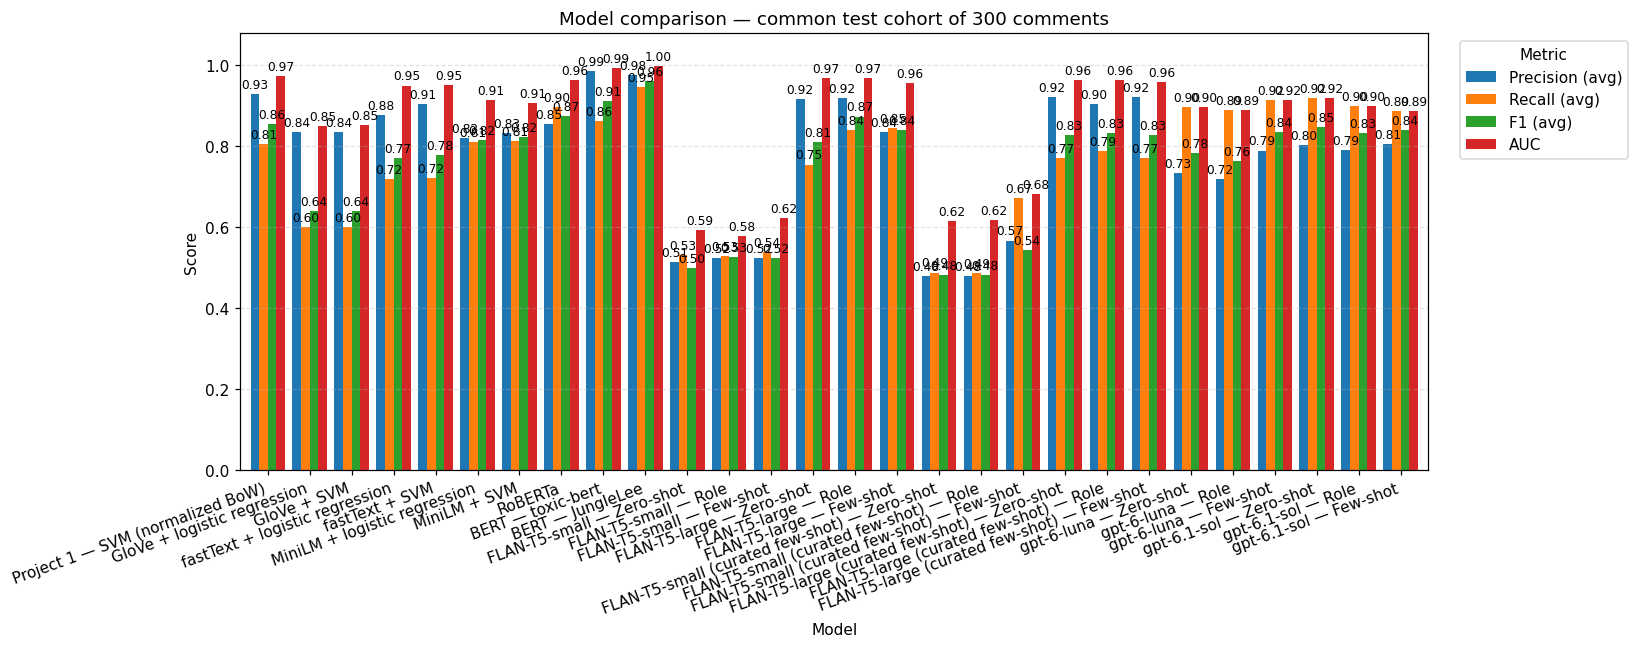

In [113]:
metric_columns = ["Precision (avg)", "Recall (avg)", "F1 (avg)", "AUC"]
ax = comparison_table[metric_columns].plot(
    kind="bar", figsize=(15, 6), ylim=(0, 1.08), width=0.82,
)
ax.set_title(f"Model comparison — common test cohort of {len(y_eval):,} comments")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


### 9.3 Confusion matrices

One matrix per model, based on each model's validation-selected threshold. Rows are the true class and columns the predicted class.

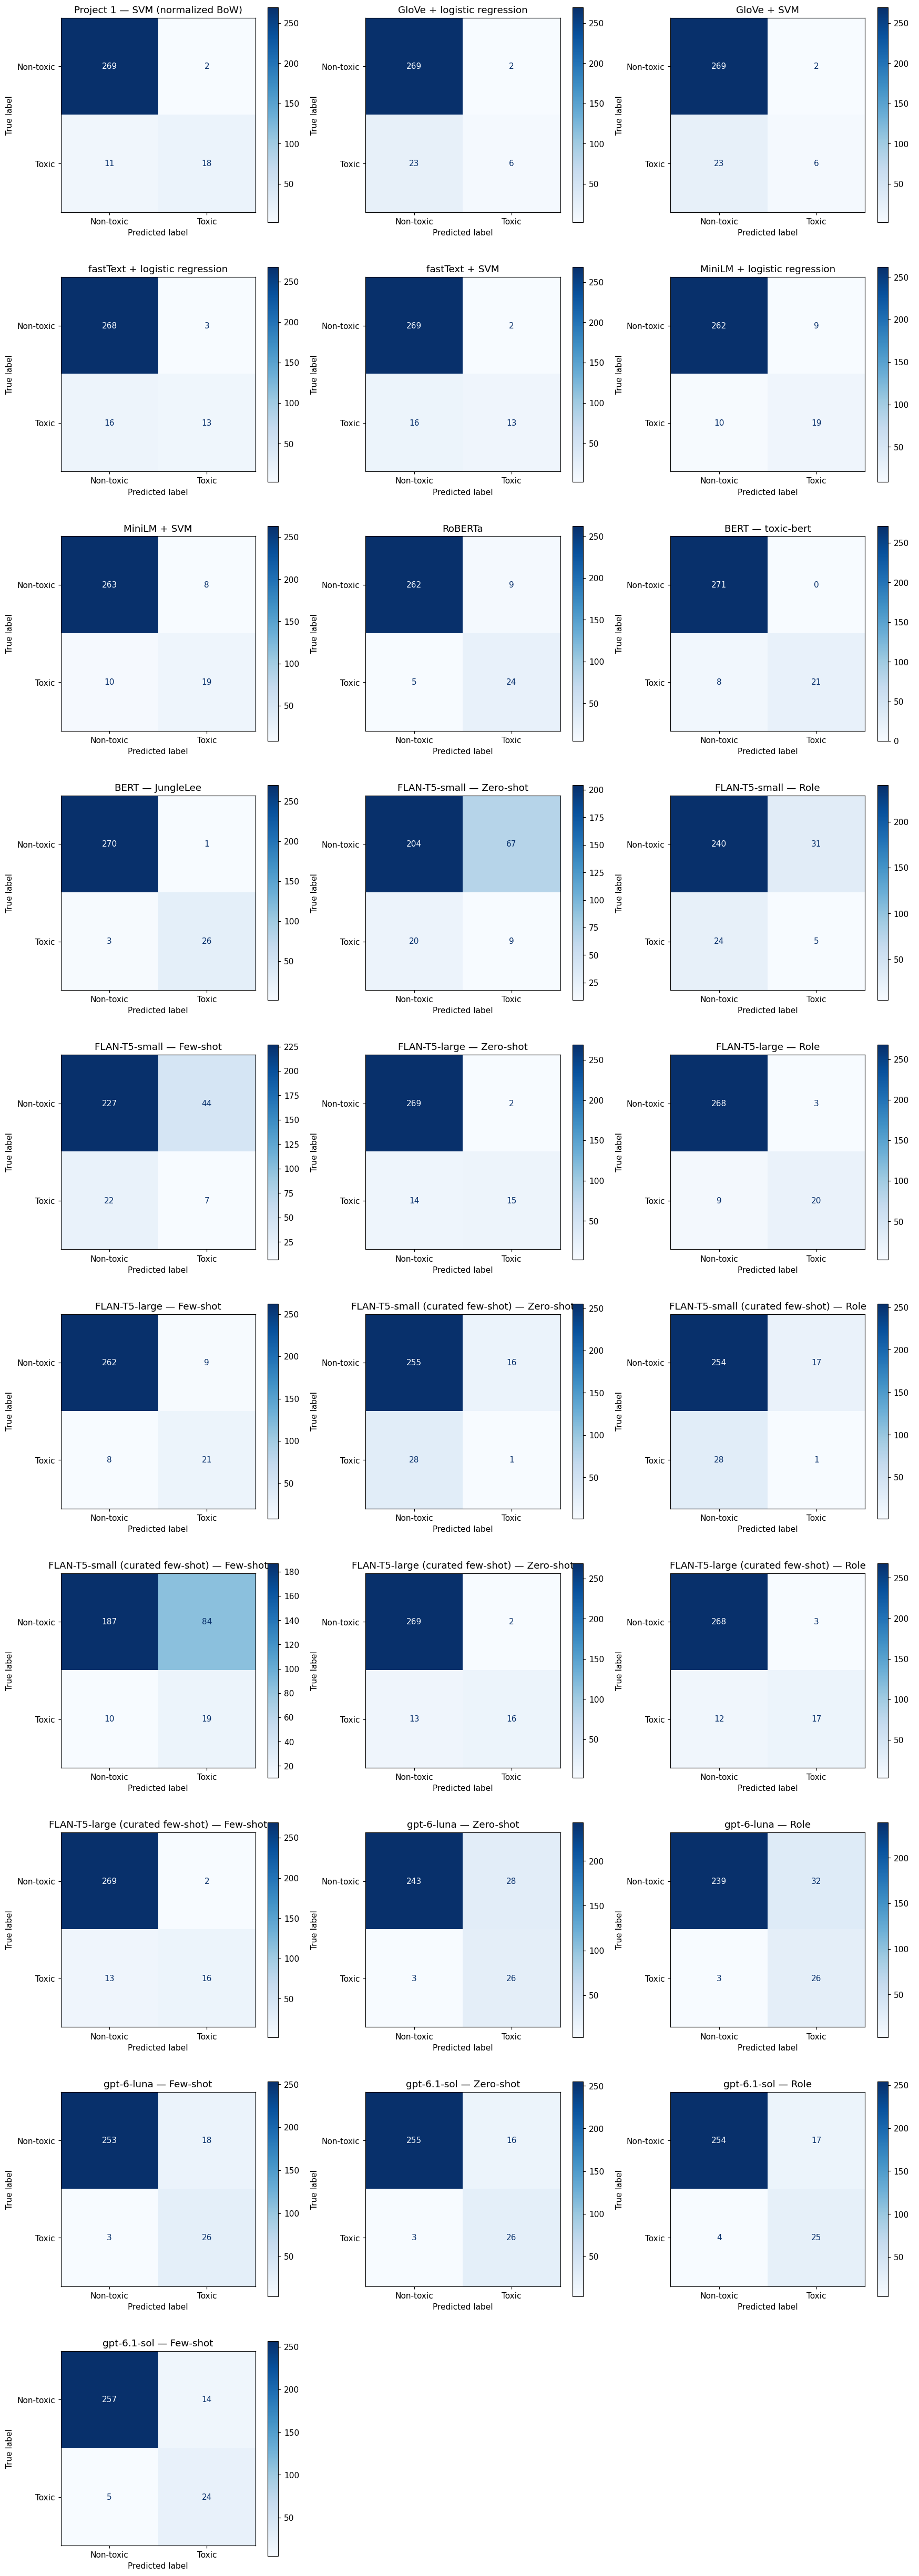

In [114]:
model_predictions = {name: result["predictions"] for name, result in model_results.items()}
n_columns = 3
n_rows = (len(model_predictions) + n_columns - 1) // n_columns
fig, axes = plt.subplots(n_rows, n_columns, figsize=(16, 4.5 * n_rows), squeeze=False)
axes = axes.ravel()
for axis, (name, predictions) in zip(axes, model_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_eval, predictions, labels=[0, 1], display_labels=["Non-toxic", "Toxic"],
        values_format="d", cmap="Blues", ax=axis,
    )
    axis.set_title(name)
for axis in axes[len(model_predictions):]:
    axis.axis("off")
plt.tight_layout()
plt.show()


### 9.4 False positives and false negatives

A **false positive** is a non-toxic comment wrongly flagged (a user falsely accused). A **false negative** is a toxic comment that slips through. The table lists the counts and the corresponding rates for each model.

In [115]:
error_rows = []

for model_name, predictions in model_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_eval,
        predictions,
        labels=[0, 1],
    ).ravel()

    error_rows.append({
        "Model": model_name,
        "True negatives": tn,
        "False positives": fp,
        "False negatives": fn,
        "True positives": tp,
        "False-positive rate (%)": 100 * fp / (tn + fp),
        "False-negative rate (%)": 100 * fn / (fn + tp),
    })

error_table = pd.DataFrame(error_rows).set_index("Model")
display(error_table.round(2))


,True negatives,False positives,False negatives,True positives,False-positive rate (%),False-negative rate (%)
Model,,,,,,
Project 1 — SVM (normalized BoW),269,2,11,18,0.74,37.93
GloVe + logistic regression,269,2,23,6,0.74,79.31
GloVe + SVM,269,2,23,6,0.74,79.31
fastText + logistic regression,268,3,16,13,1.11,55.17
fastText + SVM,269,2,16,13,0.74,55.17
MiniLM + logistic regression,262,9,10,19,3.32,34.48
MiniLM + SVM,263,8,10,19,2.95,34.48
RoBERTa,262,9,5,24,3.32,17.24
BERT — toxic-bert,271,0,8,21,0.00,27.59


### 9.5 What the numbers do not tell us: cost, bias, transparency, privacy

**Cost and deployment**. Classification time varied a lot across models. Our SVM baseline was fastest by far, around 3.8 ms per comment. BERT — JungleLee gave the best test results but took about 124 ms per comment. The hosted GPT models were much slower, somewhere between 1.4 and 5.4 seconds per comment, and cost money per call on top of that. So there's a real trade-off: for high-stakes moderation calls, the extra accuracy might be worth the wait and the cost. But for something that needs to run at scale, that slowness adds up fast. And it's not even a clean trade — several of the LLM prompts were both slower and worse than the SVM, so speed and cost aren't automatically buying you anything.

One thing worth flagging about BERT — JungleLee specifically: it was already fine-tuned on the same Jigsaw data our test set comes from. That's not overfitting exactly — overfitting is when a model memorizes noise from its own training. This is more like data leakage: the model may have already seen comments basically identical to our "held-out" test ones, so its score here might look better than it would on comments it's never encountered before.

**Bias.** Take a sentence like "She is a woman" getting flagged as toxic. Two things could cause that. First, embeddings like GloVe or fastText learn word meaning from which words show up near each other in huge amounts of text. If slurs and neutral words like "woman" keep showing up in similar contexts, their vectors end up close together in the model's internal space — not because the model thinks they mean the same thing, just because it only ever learned "these words tend to appear near similar words," and that gets mistaken for actual meaning downstream. Second, datasets like Jigsaw's are known to have more toxic-labeled comments that mention identity words, just because a lot of real harassment names who it's targeting. So a model can pick up a lazy shortcut: "identity word mentioned → probably toxic," which is obviously wrong.

Either way, the takeaway is the same: these models don't actually understand toxicity, they just pick up patterns in whatever data they were trained on — including the bad patterns. For moderation, that means you can end up silencing normal, neutral speech from the exact groups you're trying to protect.

**Transparency.** If a user asks "why was my comment flagged," the SVM baseline is the easiest to answer for — it's just weighted words, so you can point to the actual words that pushed the score up. The GPT model is the hardest: it's a huge model you only access through an API, you can't see any of its internals, all you get back is text. There's no way to actually trace why it said "yes" beyond just re-reading the prompt and guessing.

The embedding models (GloVe, fastText, MiniLM) land in the middle. The classifier sitting on top of them is fully visible, but the embeddings themselves are just long lists of numbers — no single number in there means anything on its own the way a bag-of-words feature does. So it's technically reproducible, but not really explainable in a way a normal user would find satisfying.

**Privacy.** Once you send a comment to an external LLM API, it leaves Wikipedia's systems completely and goes to run on someone else's servers. Even if a provider says they don't train on your API data by default, that's just a policy they're stating — there's no way to actually verify it from the outside, and it can change. The data still sits logged on infrastructure Wikipedia doesn't control, for however long the provider decides to keep it.

For something like Wikipedia, that's a real risk: you lose control over comments that might contain personal info, you're exposed if the provider gets breached or changes their policy, and you're trusting a company's terms you didn't write. That's basically why a lot of companies handling sensitive data just build their own models in-house instead — keeps everything under their own roof instead of depending on someone else's promises.

## 10. Which new model would we pick?

To avoid cherry-picking on the test set, the new candidate is chosen using **validation** results only (best validation F1, precision as tie-breaker). The cell then compares it with the recomputed SVM reference on the test cohort: F1, ROC AUC, precision, recall, and which model was the fastest.

In [109]:
# Select the new candidate using validation results, never test rankings.
new_candidates = validation_table.drop(index=BASELINE_NAME).sort_values(
    ["F1", "Precision"], ascending=[False, False], kind="stable",
)
selected_name = new_candidates.index[0]
reference = comparison_table.loc[BASELINE_NAME]
selected = comparison_table.loc[selected_name]

print(f"New candidate selected on validation: {selected_name}")
print(f"Reference test F1: {reference['F1 (avg)']:.4f}")
print(f"Candidate test F1: {selected['F1 (avg)']:.4f}")
print(f"Observed F1 difference: {selected['Delta F1 vs SVM']:+.4f}")
print(f"Observed ROC AUC difference: {selected['Delta AUC vs SVM']:+.4f}")
print(f"Precision: {reference['Precision (avg)']:.4f} -> {selected['Precision (avg)']:.4f}")
print(f"Recall: {reference['Recall (avg)']:.4f} -> {selected['Recall (avg)']:.4f}")
if selected["Delta F1 vs SVM"] > 0:
    print("The validation-selected new approach has higher observed macro-averaged F1 on this test cohort.")
else:
    print("An improvement in macro-averaged F1 is not demonstrated for the validation-selected candidate.")
print(f"Fastest observed inference: {comparison_table['Time per comment (ms)'].idxmin()}")
print("Use the common-cohort results above when writing the project discussion.")


New candidate selected on validation: BERT — toxic-bert
Reference test F1: 0.8556
Candidate test F1: 0.9127
Observed F1 difference: +0.0572
Observed ROC AUC difference: +0.0197
Precision: 0.9304 -> 0.9857
Recall: 0.8067 -> 0.8621
The validation-selected new approach has higher observed macro-averaged F1 on this test cohort.
Fastest observed inference: GloVe + SVM
Use the common-cohort results above when writing the project discussion.


## 11. AI and external-tool assistance

ChatGPT/Codex assisted with restructuring, English wording, VS Code setup, and
the corrected comparison protocol. The notebook includes a recomputed SVM
reference, validation-only parameter/threshold selection, and common test metrics.

The code was checked for Python syntax and its split, threshold selection, and
reporting logic were exercised on small control data. The complete neural-model
experiment was not executed in the editing environment. Run the notebook with
the complete dataset and the configured models to obtain actual project results.

Implementation references:
[scikit-learn: data leakage](https://scikit-learn.org/stable/common_pitfalls.html),
[threshold selection](https://scikit-learn.org/stable/modules/classification_threshold.html),
[precision-recall curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html),
[RoBERTa model card](https://huggingface.co/unitary/unbiased-toxic-roberta),
and [FLAN-T5-small model card](https://huggingface.co/google/flan-t5-small).
